# Supervised Learning - Foundations Project: ReCell

## Problem Statement

### Business Context

Buying and selling used phones and tablets used to be something that happened on a handful of online marketplace sites. But the used and refurbished device market has grown considerably over the past decade, and a new IDC (International Data Corporation) forecast predicts that the used phone market would be worth \\$52.7bn by 2023 with a compound annual growth rate (CAGR) of 13.6% from 2018 to 2023. This growth can be attributed to an uptick in demand for used phones and tablets that offer considerable savings compared with new models.

Refurbished and used devices continue to provide cost-effective alternatives to both consumers and businesses that are looking to save money when purchasing one. There are plenty of other benefits associated with the used device market. Used and refurbished devices can be sold with warranties and can also be insured with proof of purchase. Third-party vendors/platforms, such as Verizon, Amazon, etc., provide attractive offers to customers for refurbished devices. Maximizing the longevity of devices through second-hand trade also reduces their environmental impact and helps in recycling and reducing waste. The impact of the COVID-19 outbreak may further boost this segment as consumers cut back on discretionary spending and buy phones and tablets only for immediate needs.


### Objective

The rising potential of this comparatively under-the-radar market fuels the need for an ML-based solution to develop a dynamic pricing strategy for used and refurbished devices. ReCell, a startup aiming to tap the potential in this market, has hired you as a data scientist. They want you to analyze the data provided and build a linear regression model to predict the price of a used phone/tablet and identify factors that significantly influence it.


### Data Description

The data contains the different attributes of used/refurbished phones and tablets. The data was collected in the year 2021. The detailed data dictionary is given below.


- brand_name: Name of manufacturing brand
- os: OS on which the device runs
- screen_size: Size of the screen in cm
- 4g: Whether 4G is available or not
- 5g: Whether 5G is available or not
- main_camera_mp: Resolution of the rear camera in megapixels
- selfie_camera_mp: Resolution of the front camera in megapixels
- int_memory: Amount of internal memory (ROM) in GB
- ram: Amount of RAM in GB
- battery: Energy capacity of the device battery in mAh
- weight: Weight of the device in grams
- release_year: Year when the device model was released
- days_used: Number of days the used/refurbished device has been used
- normalized_new_price: Normalized price of a new device of the same model in euros
- normalized_used_price: Normalized price of the used/refurbished device in euros

## Importing necessary libraries

In [2]:
# Installing the libraries with the specified version.
# uncomment and run the following line if Google Colab is being used
!pip install scikit-learn==1.2.2 seaborn==0.13.1 matplotlib==3.7.1 numpy==1.25.2 pandas==1.5.3 -q --user

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 48.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.0/38.0 MB 17.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 103.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This erro

In [ ]:
# Installing the libraries with the specified version.
# uncomment and run the following lines if Jupyter Notebook is being used
# !pip install scikit-learn==1.2.2 seaborn==0.11.1 matplotlib==3.3.4 numpy==1.24.3 pandas==1.5.2 -q --user

**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again.*

In [3]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd
import matplotlib

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

# split the data into train and test
from sklearn.model_selection import train_test_split

# to build linear regression_model
import statsmodels.api as sm

# to check model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Loading the dataset

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Data Overview

- Observations
- Sanity checks

In [42]:
data = pd.read_csv('/content/drive/MyDrive/Python Course/used_device_data.csv')


In [7]:
#Displaying the first few rows of the dataset
data.head()

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
0,Honor,Android,14.50,yes,no,13.0,5.0,64.0,3.0,3020.0,146.0,2020,127,4.307572,4.715100
1,Honor,Android,17.30,yes,yes,13.0,16.0,128.0,8.0,4300.0,213.0,2020,325,5.162097,5.519018
2,Honor,Android,16.69,yes,yes,13.0,8.0,128.0,8.0,4200.0,213.0,2020,162,5.111084,5.884631
3,Honor,Android,25.50,yes,yes,13.0,8.0,64.0,6.0,7250.0,480.0,2020,345,5.135387,5.630961
4,Honor,Android,15.32,yes,no,13.0,8.0,64.0,3.0,5000.0,185.0,2020,293,4.389995,4.947837


*   The dataset contains information about different phones and tablets.
*   Release year seems to be 2020 for most of the items.



**Checking the shape of the dataset**

In [7]:
print(data.shape)       # rows, columns
print(data.dtypes)

(3454, 15)
brand_name                object
os                        object
screen_size              float64
4g                        object
5g                        object
main_camera_mp           float64
selfie_camera_mp         float64
int_memory               float64
ram                      float64
battery                  float64
weight                   float64
release_year               int64
days_used                  int64
normalized_used_price    float64
normalized_new_price     float64
dtype: object


*   The dataset contains information (15 attributes) about 3454 Buying and selling used phones and tablets.

**Checking the data types of the columns for the dataset**

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3454 entries, 0 to 3453
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   brand_name             3454 non-null   object 
 1   os                     3454 non-null   object 
 2   screen_size            3454 non-null   float64
 3   4g                     3454 non-null   object 
 4   5g                     3454 non-null   object 
 5   main_camera_mp         3275 non-null   float64
 6   selfie_camera_mp       3452 non-null   float64
 7   int_memory             3450 non-null   float64
 8   ram                    3450 non-null   float64
 9   battery                3448 non-null   float64
 10  weight                 3447 non-null   float64
 11  release_year           3454 non-null   int64  
 12  days_used              3454 non-null   int64  
 13  normalized_used_price  3454 non-null   float64
 14  normalized_new_price   3454 non-null   float64
dtypes: f



*   There are 11 numeric (float and int type) and 4 string (object type) columns in the data
*   The target variable is the "normalized_used_price" to predict the price of a used/refurbished device, which is of float type




**Statistical summary of the dataset**

In [36]:
data.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand_name,3454,34,Others,502,NaN,NaN,NaN,NaN,NaN,NaN,NaN
os,3454,4,Android,3214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
screen_size,3454.0,NaN,NaN,NaN,13.713115,3.80528,5.08,12.7,12.83,15.34,30.71
4g,3454,2,yes,2335,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5g,3454,2,no,3302,NaN,NaN,NaN,NaN,NaN,NaN,NaN
main_camera_mp,3275.0,NaN,NaN,NaN,9.460208,4.815461,0.08,5.0,8.0,13.0,48.0
selfie_camera_mp,3452.0,NaN,NaN,NaN,6.554229,6.970372,0.0,2.0,5.0,8.0,32.0
int_memory,3450.0,NaN,NaN,NaN,54.573099,84.972371,0.01,16.0,32.0,64.0,1024.0
ram,3450.0,NaN,NaN,NaN,4.036122,1.365105,0.02,4.0,4.0,4.0,12.0
battery,3448.0,NaN,NaN,NaN,3133.402697,1299.682844,500.0,2100.0,3000.0,4000.0,9720.0


*   We can see that the phone's normalized_used_price vary between 1.5 and 6.6, which suggests that the anime were rated on a scale of 0-5
*   The general normalized_used_price is 4.40.
*   Android is the most occurring OS.
*   'normalized_new_price' might be the strong predictor.
*   The number of release year varies from 2015 to 2020.








**Checking for duplicate values**

In [10]:
data.duplicated().sum()

np.int64(0)


*   There are no duplicate values in the data

**Checking for missing values**

In [37]:
data.isnull().sum()

,0
brand_name,0
os,0
screen_size,0
4g,0
5g,0
main_camera_mp,179
selfie_camera_mp,2
int_memory,4
ram,4
battery,6




*   There are missing values in many columns.



In [92]:
# creating a copy of the data so that original data remains unchanged
df = data.copy()

## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions**:

1. What does the distribution of normalized used device prices look like?
2. What percentage of the used device market is dominated by Android devices?
3. The amount of RAM is important for the smooth functioning of a device. How does the amount of RAM vary with the brand?
4. A large battery often increases a device's weight, making it feel uncomfortable in the hands. How does the weight vary for phones and tablets offering large batteries (more than 4500 mAh)?
5. Bigger screens are desirable for entertainment purposes as they offer a better viewing experience. How many phones and tablets are available across different brands with a screen size larger than 6 inches?
6. A lot of devices nowadays offer great selfie cameras, allowing us to capture our favorite moments with loved ones. What is the distribution of devices offering greater than 8MP selfie cameras across brands?
7. Which attributes are highly correlated with the normalized price of a used device?

In [71]:
def histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (15,10))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a triangle will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [72]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 2, 6))
    else:
        plt.figure(figsize=(n + 2, 6))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        hue=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n],
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

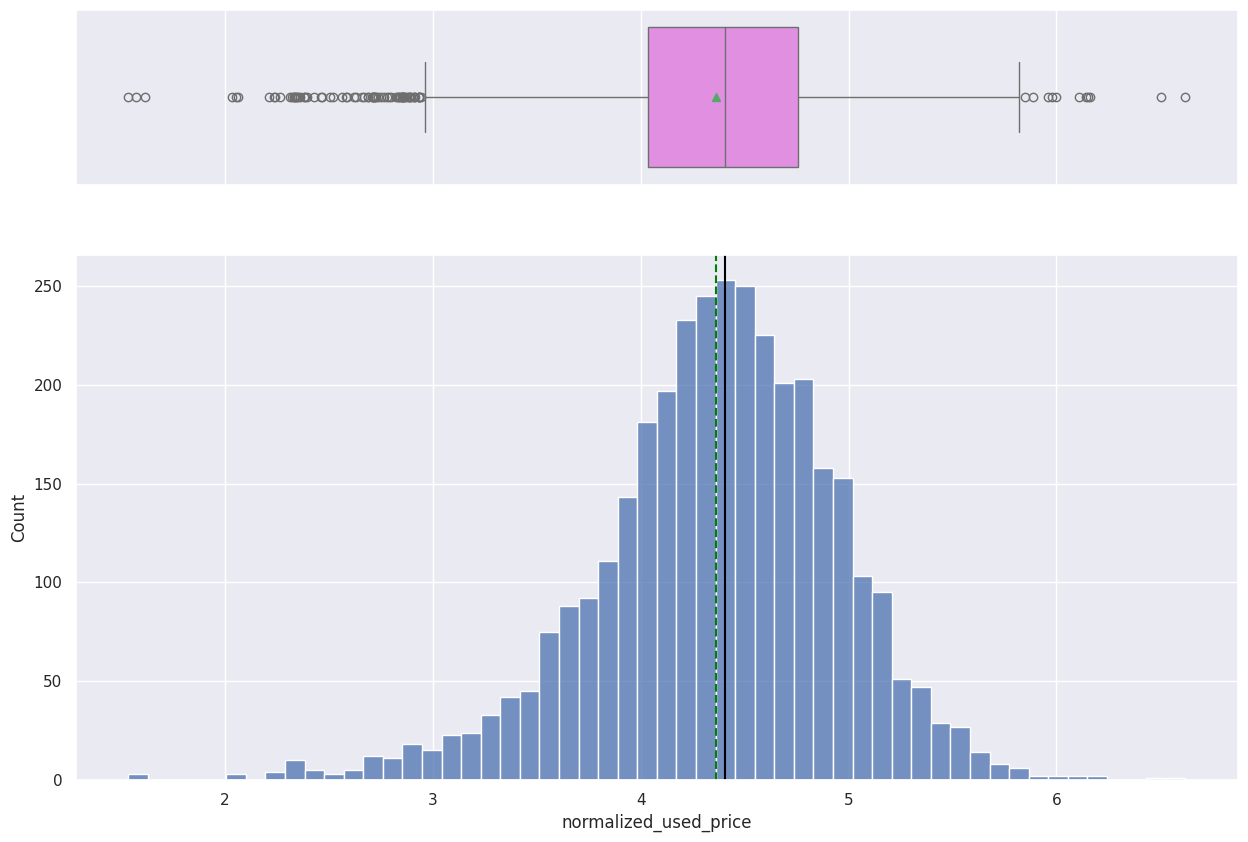

In [93]:
histogram_boxplot(df, "normalized_used_price")

* The normalized_used_price are close to normally distributed with fatter tails
* Most values are tightly clustered, but extreme low/high values exist.
* Dependent variable (normalized_used_price) is nearly normal, centered around 4.3, with some outliers



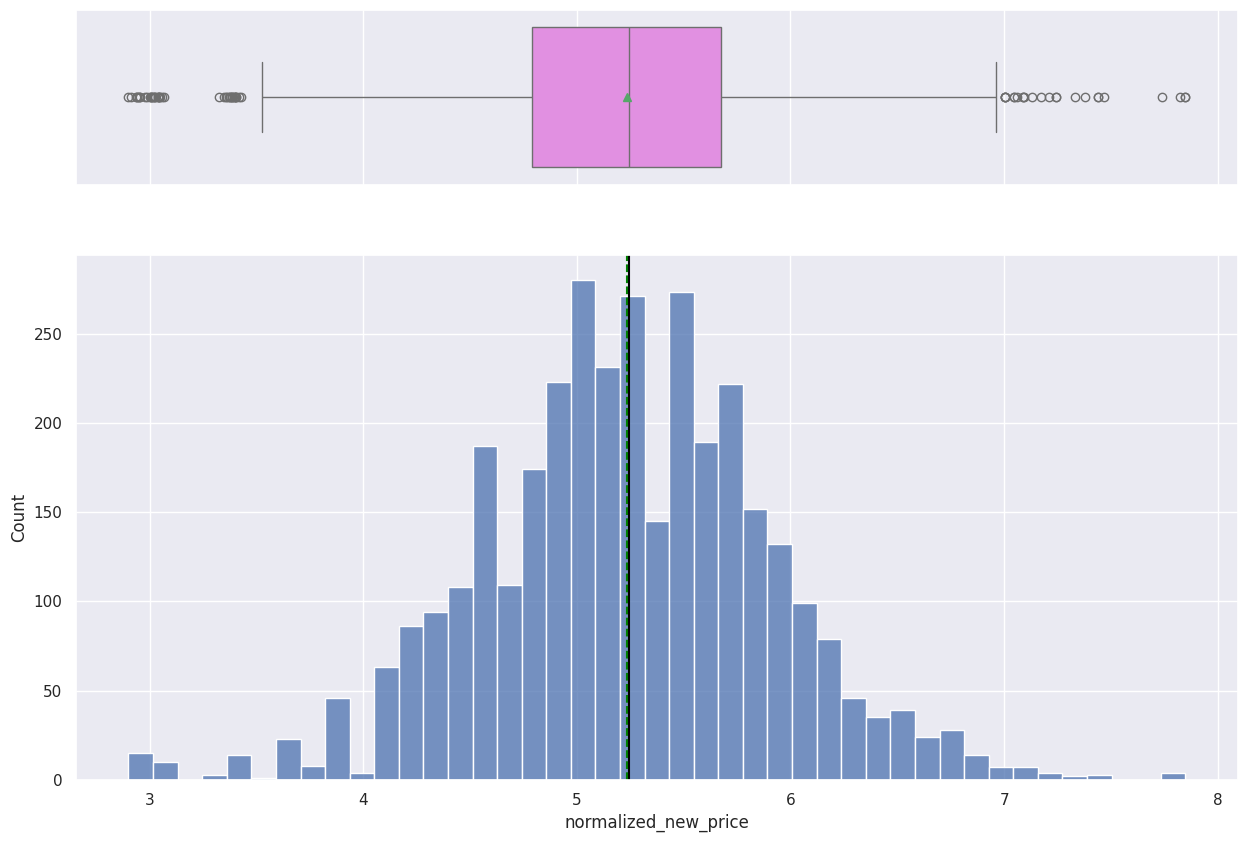

In [94]:
histogram_boxplot(df, "normalized_new_price")

* Outliers exist at both low (below ~3.5) and high (above ~7.0).
* Spread is wider compared to normalized_used_price.
* Shape looks close to normal, but with slightly heavier tails (some extreme new-price values)

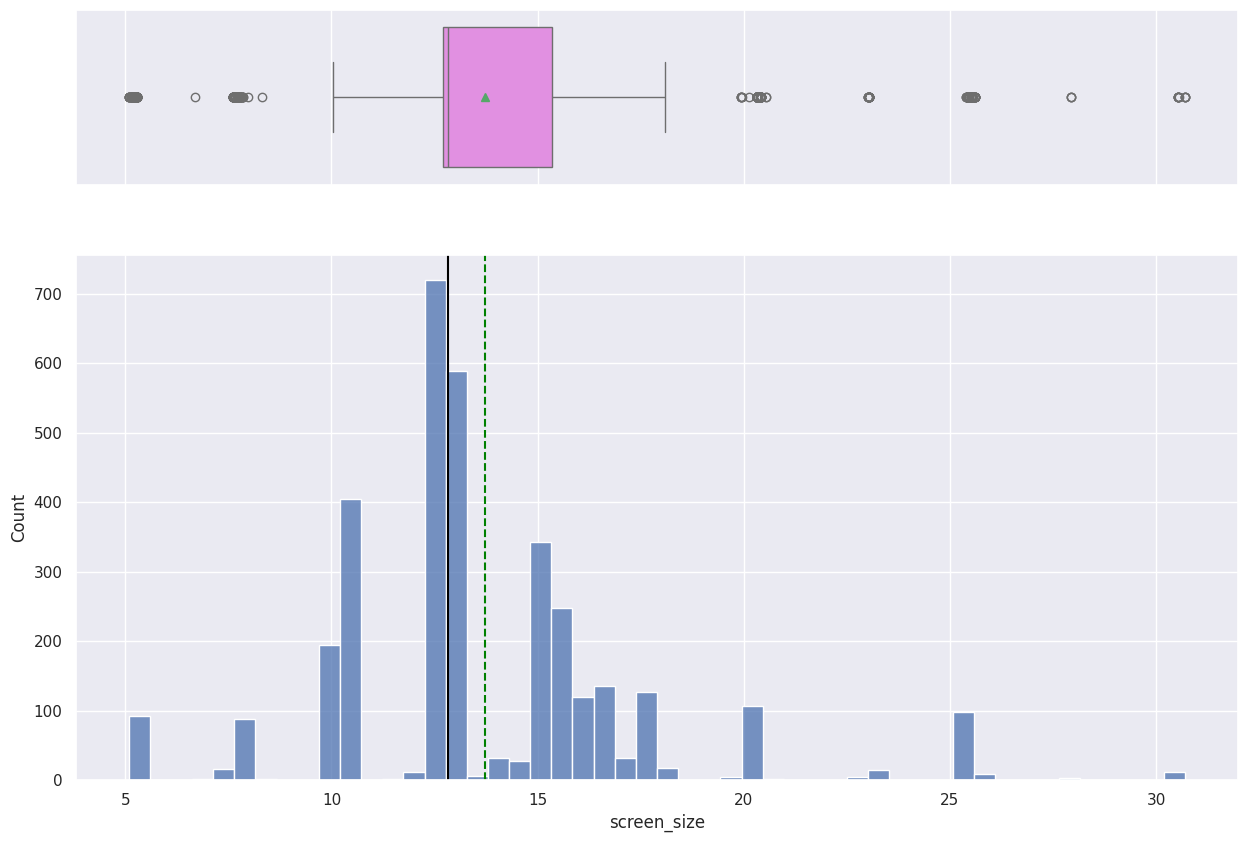

In [95]:
histogram_boxplot(df, "screen_size", bins=50)

*  Screen_size shows clear clusters that represent different device types.

* Outliers are meaningful (small phones, large tablets) and should be treated as valid, not errors.

* This feature is likely important in predicting used price, since larger screens (especially tablets).




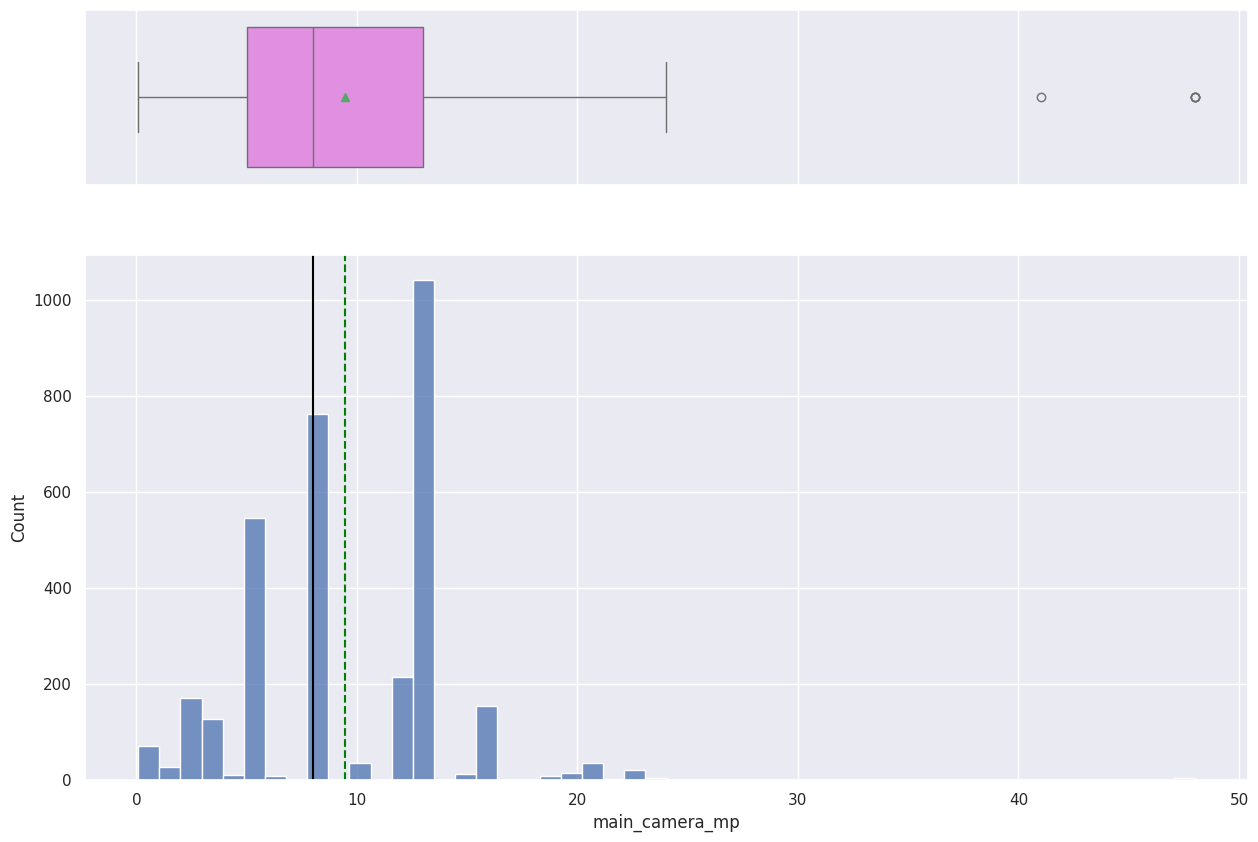

In [96]:
histogram_boxplot(df, "main_camera_mp", bins=50)

Clear peaks around:

3-5 (small/older phones).

5–8 (mid range phone, tablets)

13–13 ( smart phones)

Distribution is multi-modal → multiple peaks due to different device categories (small phones, regular smartphones, tablets).

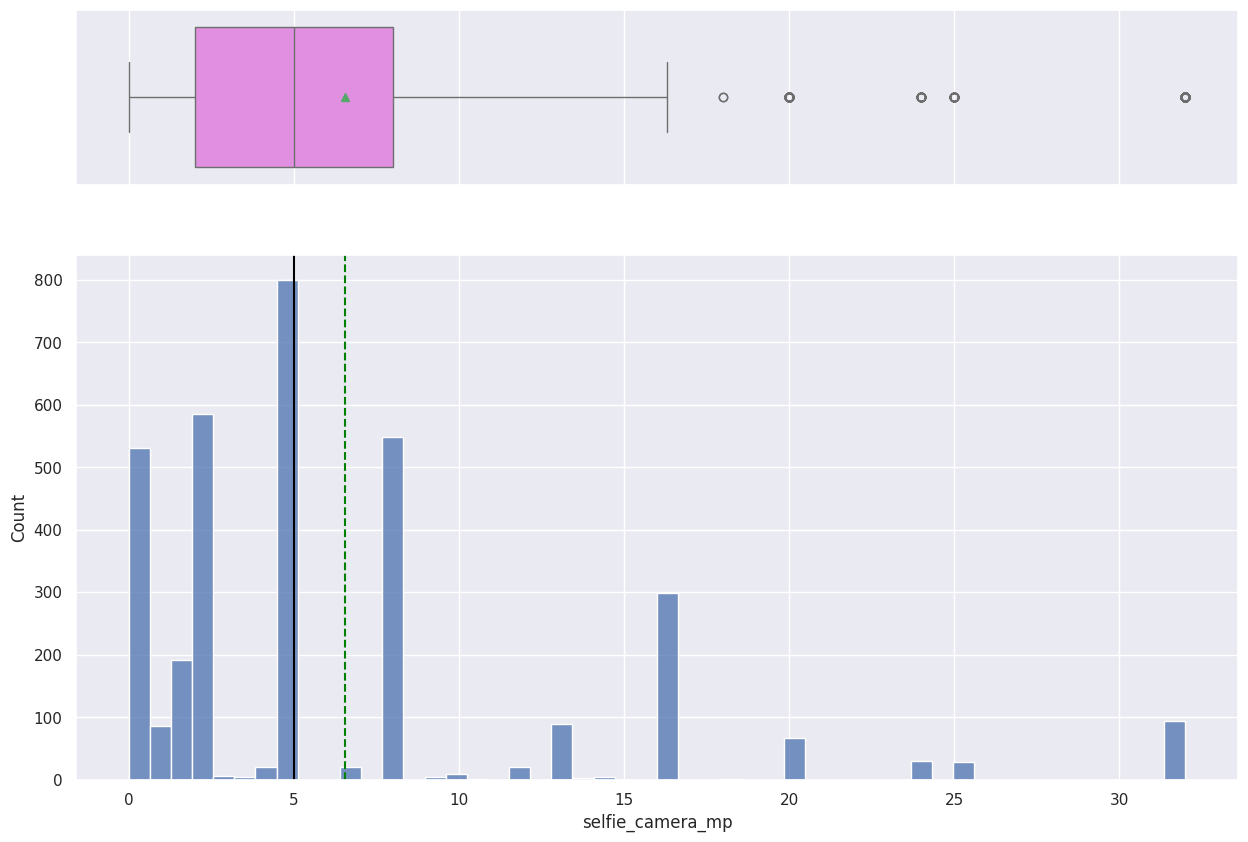

In [97]:
histogram_boxplot(df, "selfie_camera_mp", bins=50)

* Mostly selfie camera seems to be blongs 0-5 mega pixel.
* Distribution is multi-modal as graph shoes 80-90 phones has 32 mp has selfie camera.

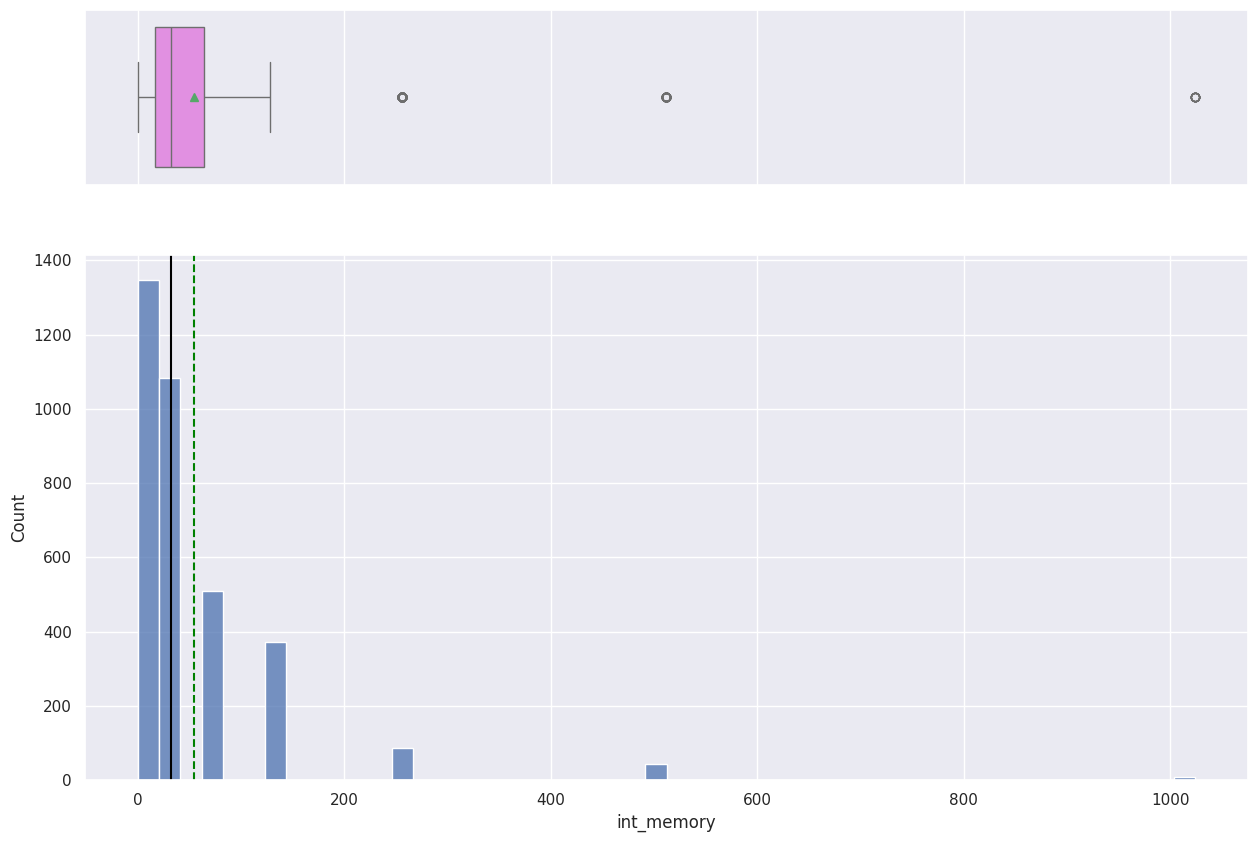

In [98]:
histogram_boxplot(df, "int_memory", bins=50)

*   The distribution for int_memory is heavily right-skewed, and most of the phone's memory having less than 150 memory.
*  Big count showes for having less int_memory.



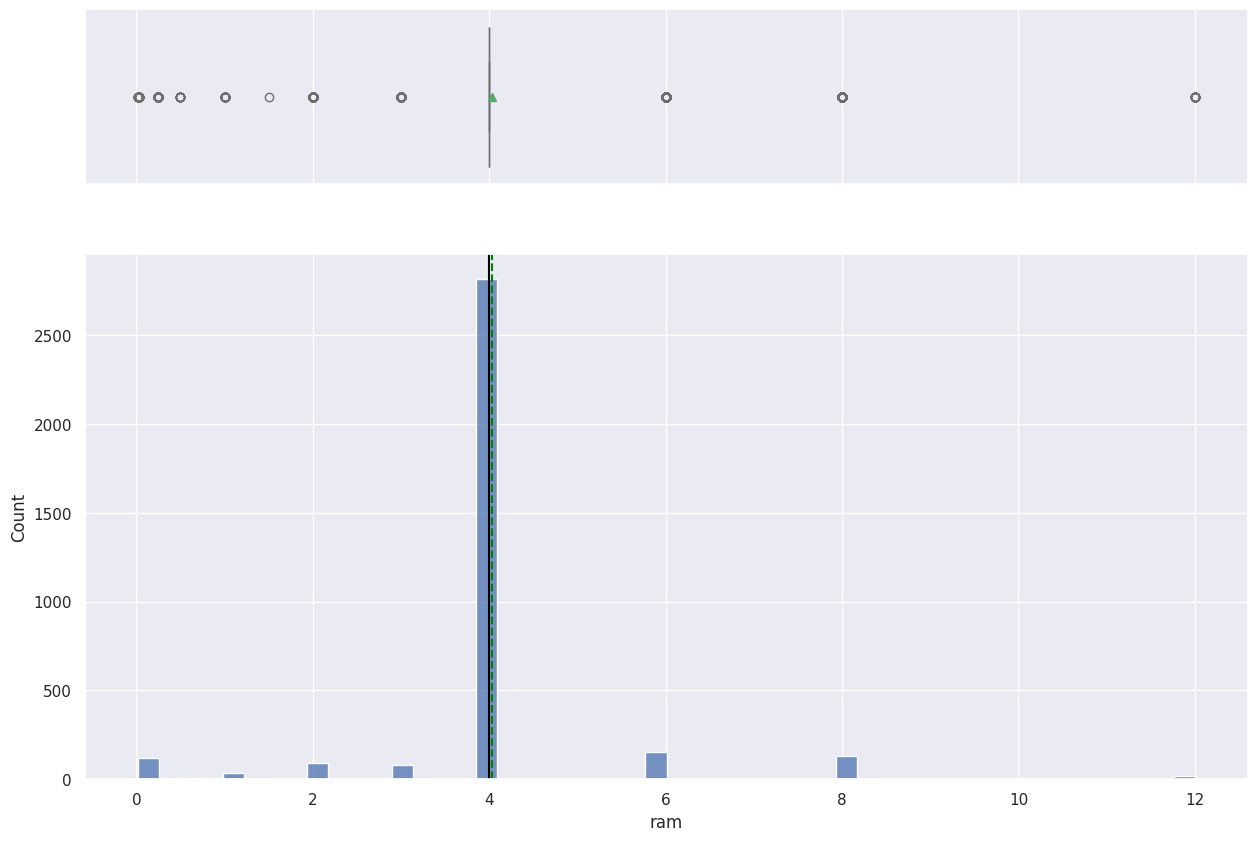

In [99]:
histogram_boxplot(df, "ram", bins=50)



*  The distribution seems to be heavily centered. Mostly items has 4gb ram.
*   Ram is nearly normal, centered around 4, with some outliers.



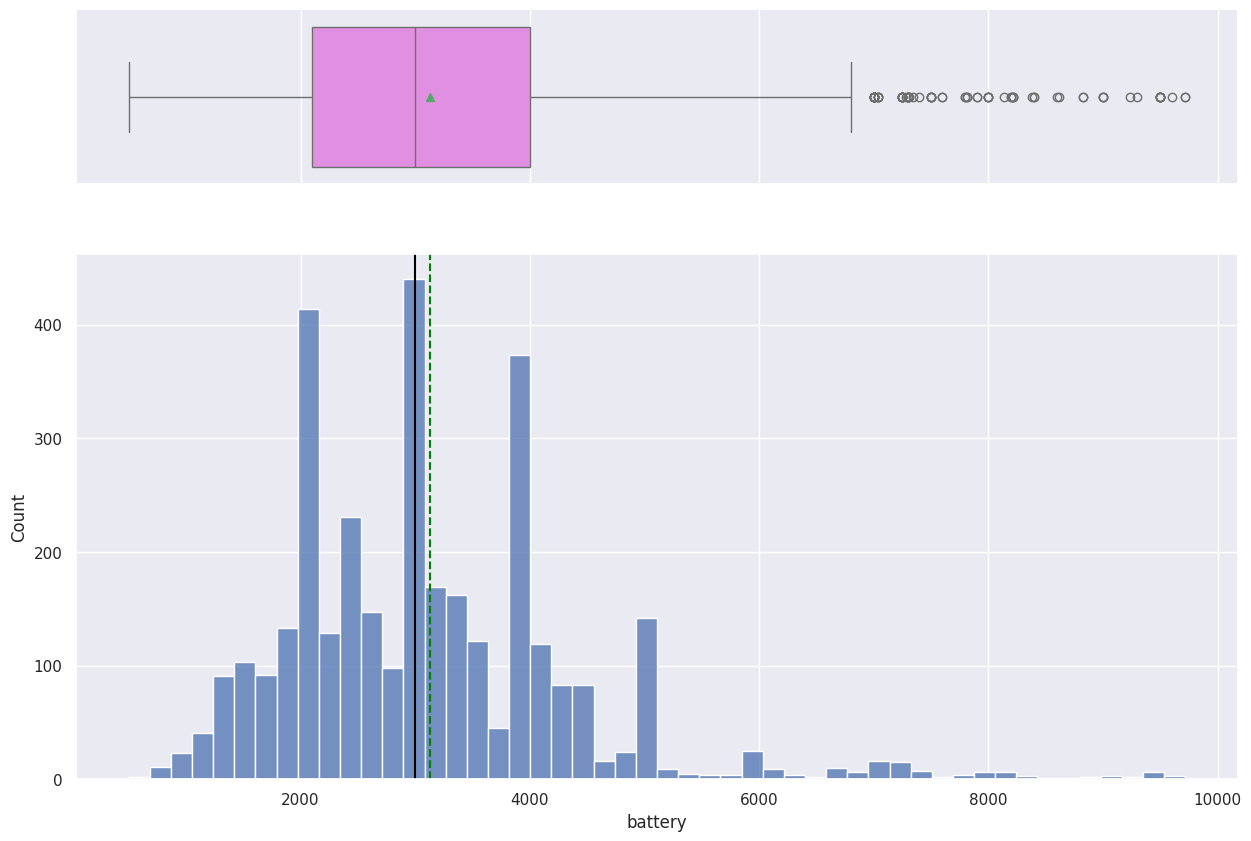

In [100]:
histogram_boxplot(df, "battery", bins=50)



*   The distribution for battery column is right-skewed with a median runtime of less than 5000.
*  


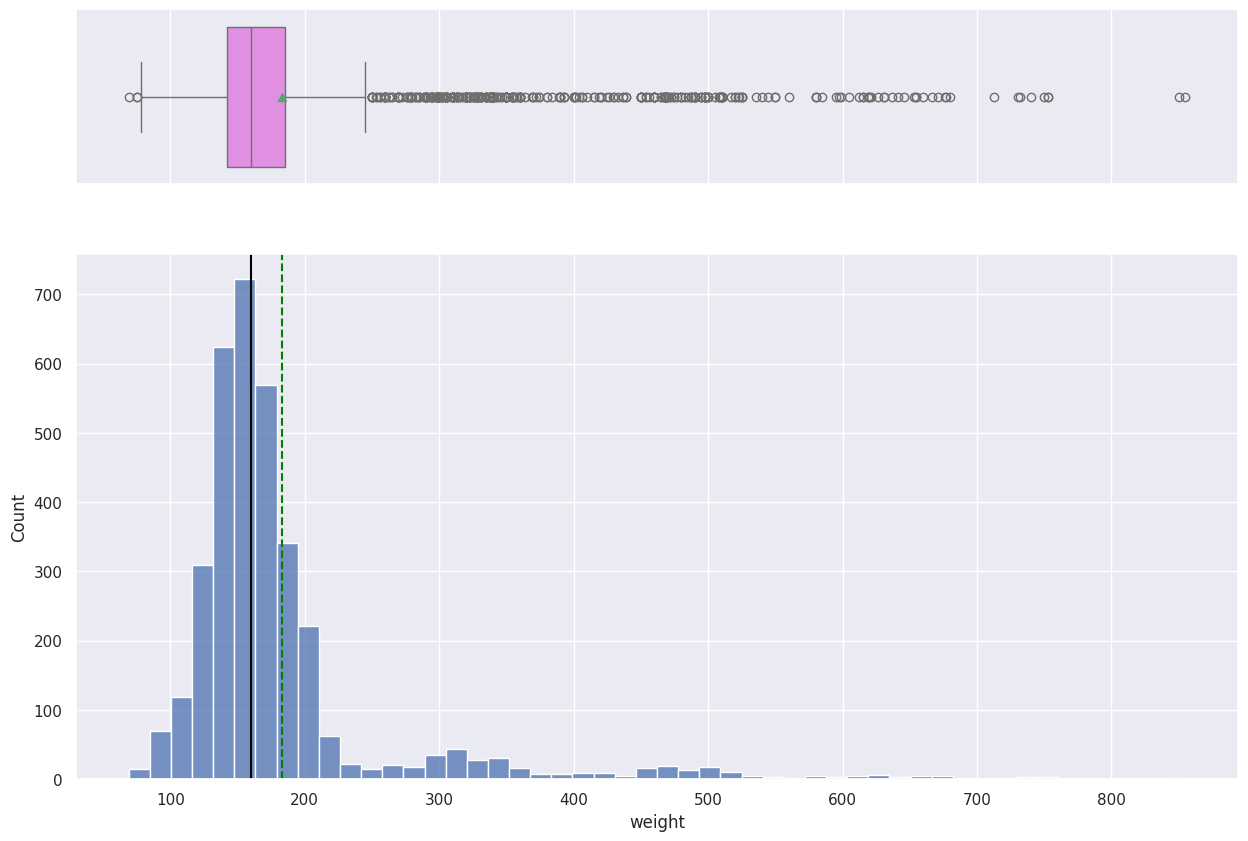

In [101]:
histogram_boxplot(df, "weight", bins=50)

* The distribution is right-skewed,and mostly iotems weigh below 200.

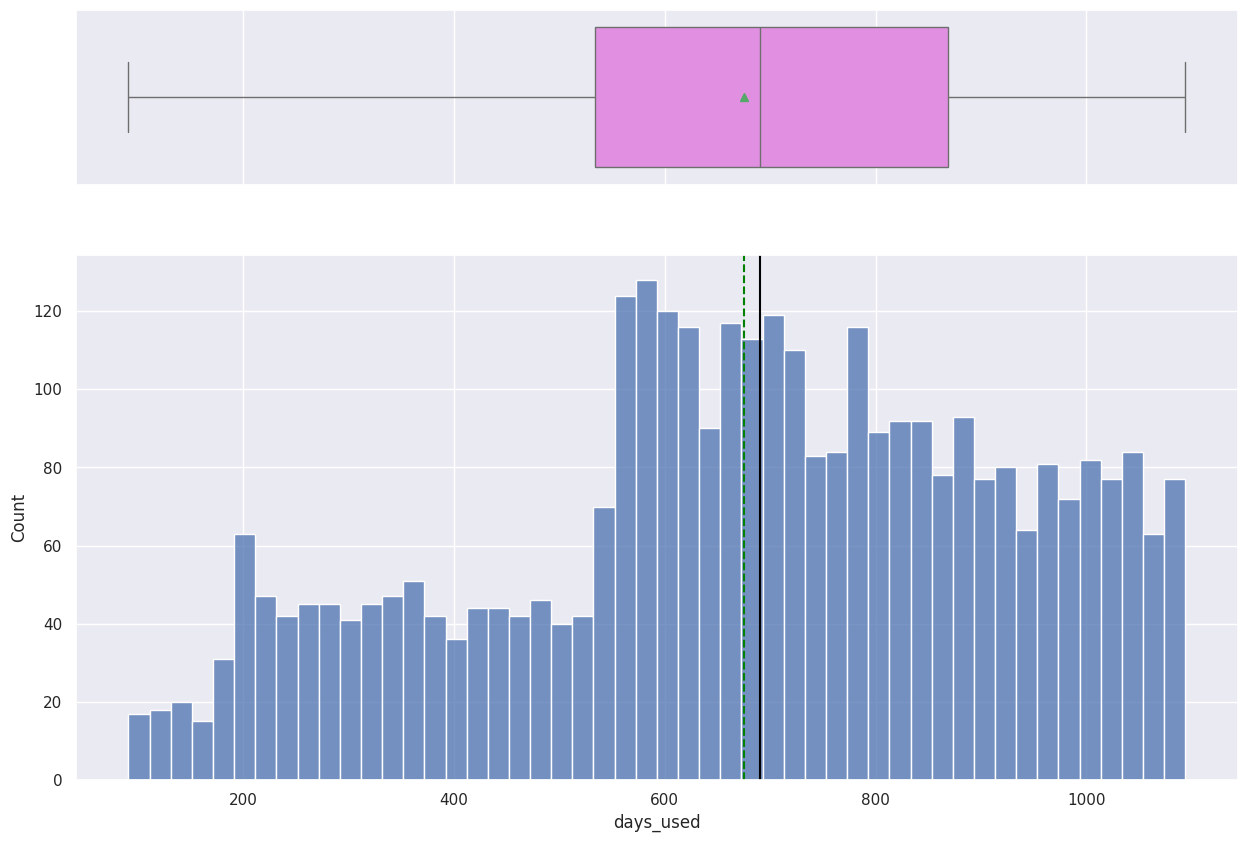

In [102]:
histogram_boxplot(df, "days_used", bins=50)

* The distribution is heavily left-skewed and seems to be bimodal, mostly items has been used more than 500 days.

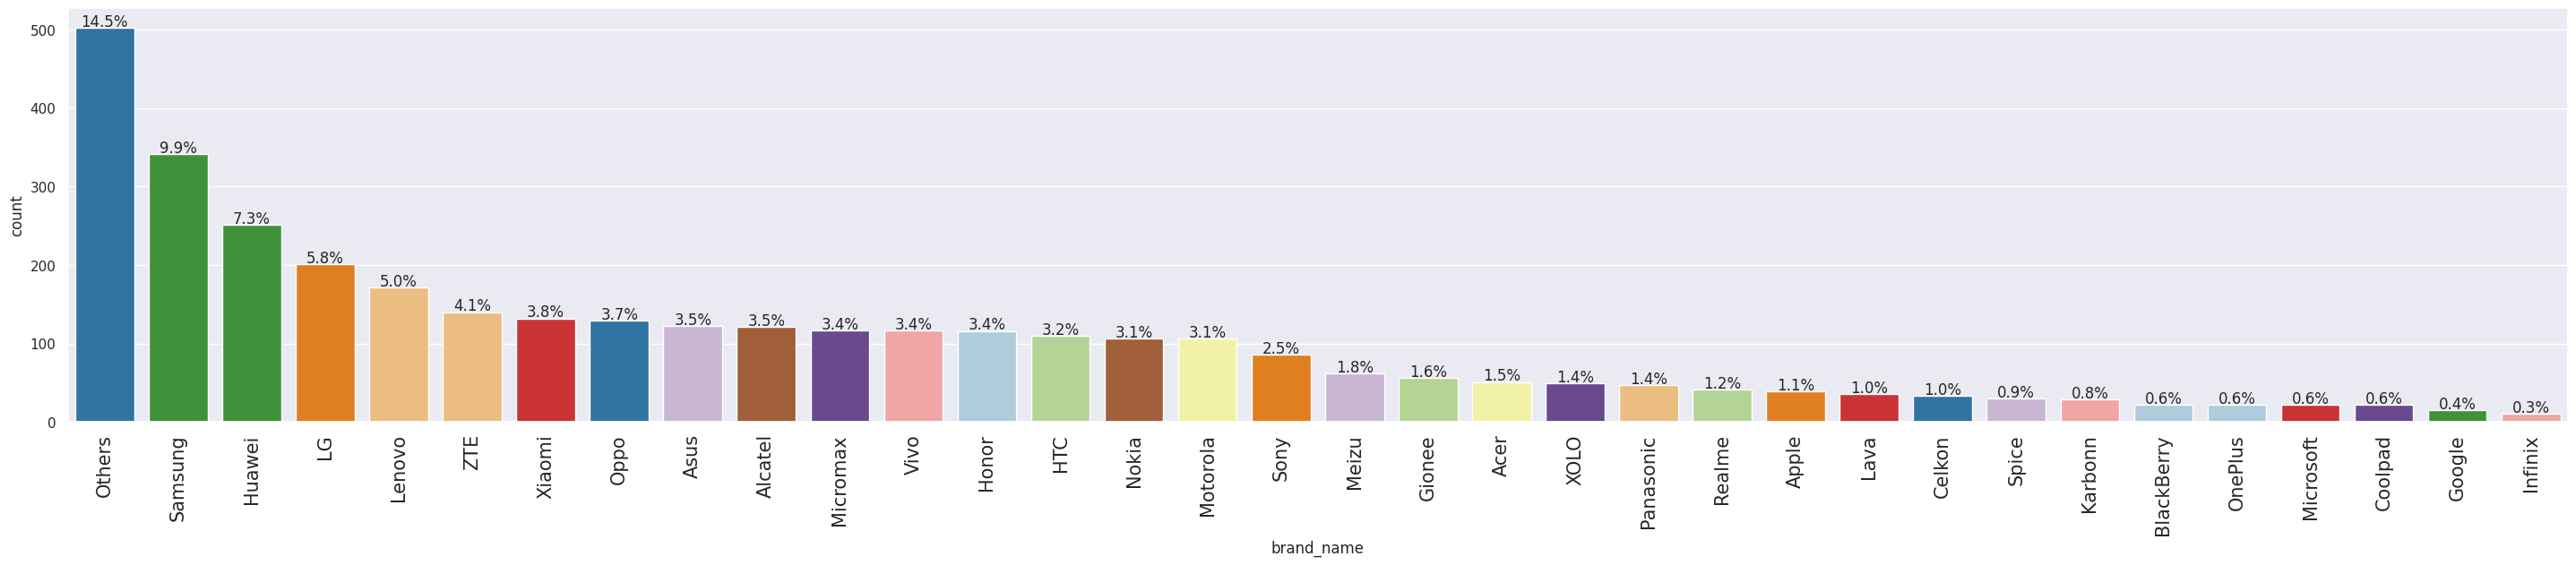

In [103]:
labeled_barplot(df, "brand_name", perc=True)



*   Approximately 9.9% of the itmes belongs to Samsung.
*   14.5% goes to others which is surprising as we have almost every brand cover. surprisingly we have 1.1% Apple items.


In [105]:
# creating a list of numerical columns
num_cols = df.select_dtypes(include=np.number).columns.tolist()



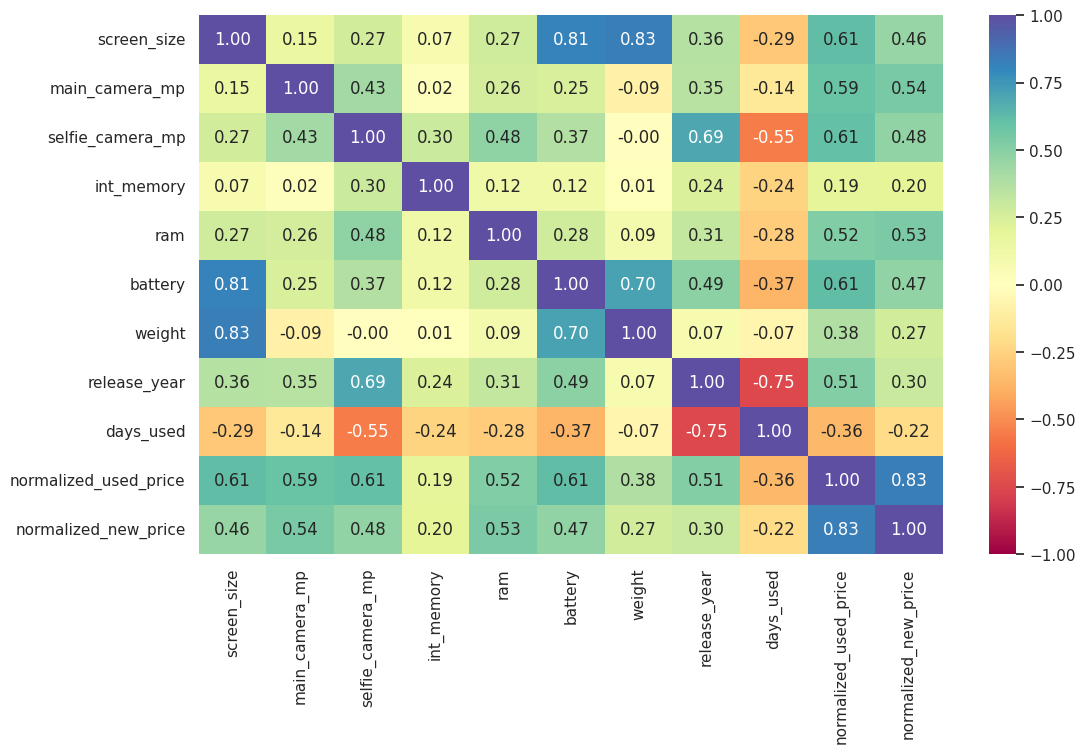

In [106]:
plt.figure(figsize=(12, 7))
sns.heatmap(
    df[num_cols].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral"
)
plt.show()

*   Screen size is positively correlated with both battery and weight because larger devices need more power (bigger batteries) and more material (glass, casing, internal components), which naturally makes them heavier.
* The heatmap likely shows a positive correlation between release_year and selfie_camera_mp.
* Meaning: newer devices (higher release year) tend to have higher-resolution selfie cameras.


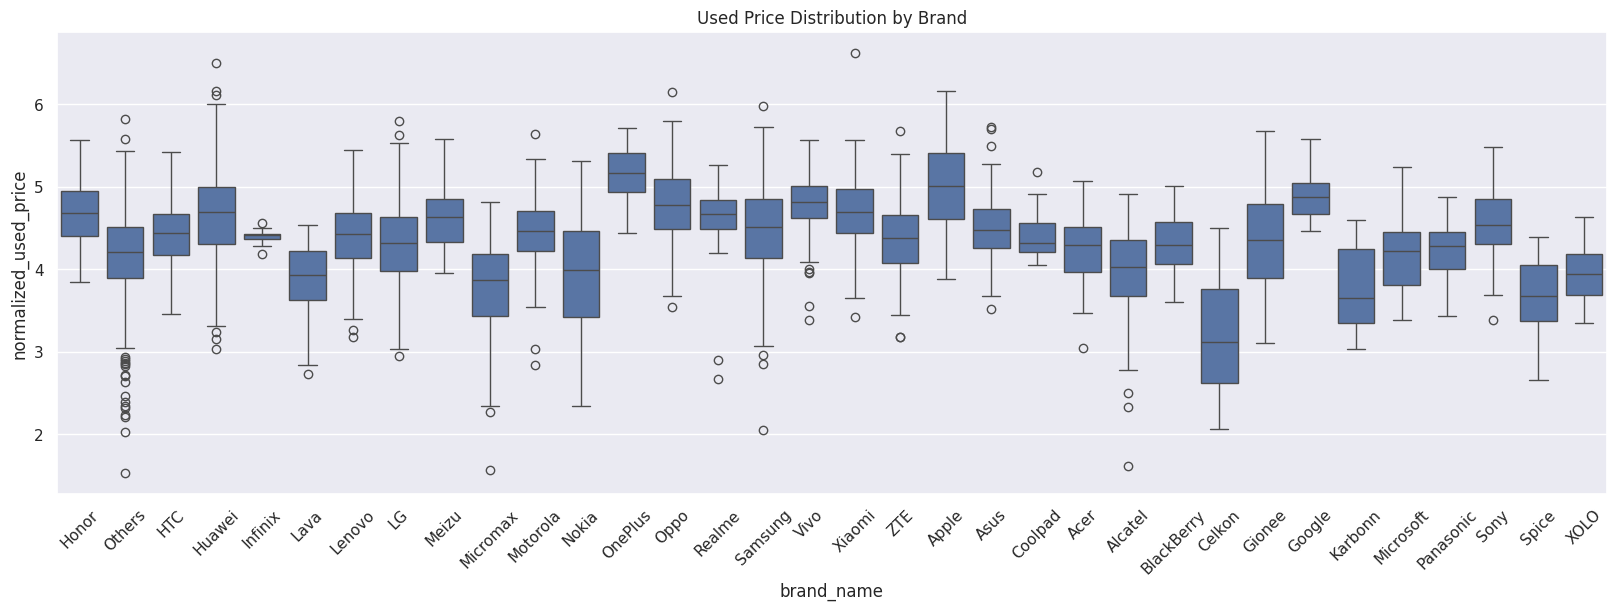

In [107]:
plt.figure(figsize=(20,6))
sns.boxplot(x="brand_name", y="normalized_used_price", data=df)
plt.xticks(rotation=45)
plt.title("Used Price Distribution by Brand")
plt.show()

* Oneplus phones has highest prices.
* Samsung item are moderateprices.


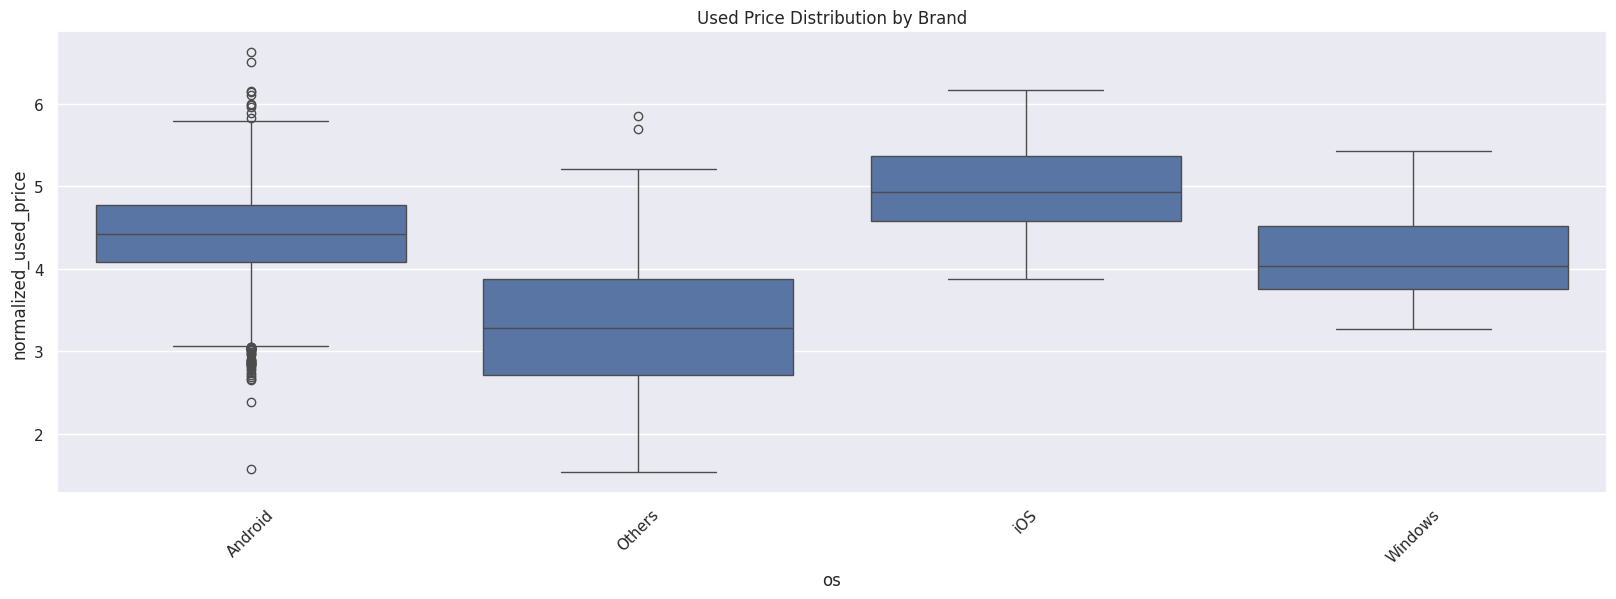

In [108]:
plt.figure(figsize=(20,6))
sns.boxplot(x="os", y="normalized_used_price", data=df)
plt.xticks(rotation=45)
plt.title("Used Price Distribution by Brand")
plt.show()

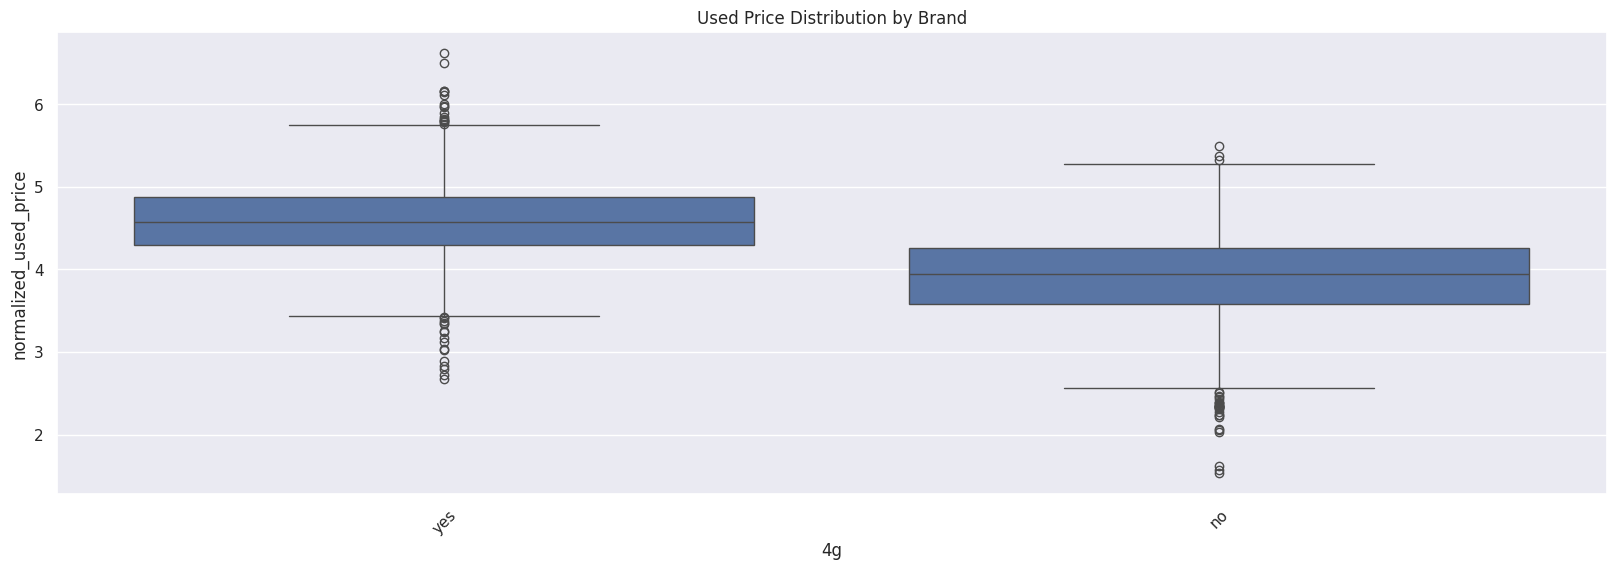

In [109]:
plt.figure(figsize=(20,6))
sns.boxplot(x="4g", y="normalized_used_price", data=df)
plt.xticks(rotation=45)
plt.title("Used Price Distribution by Brand")
plt.show()

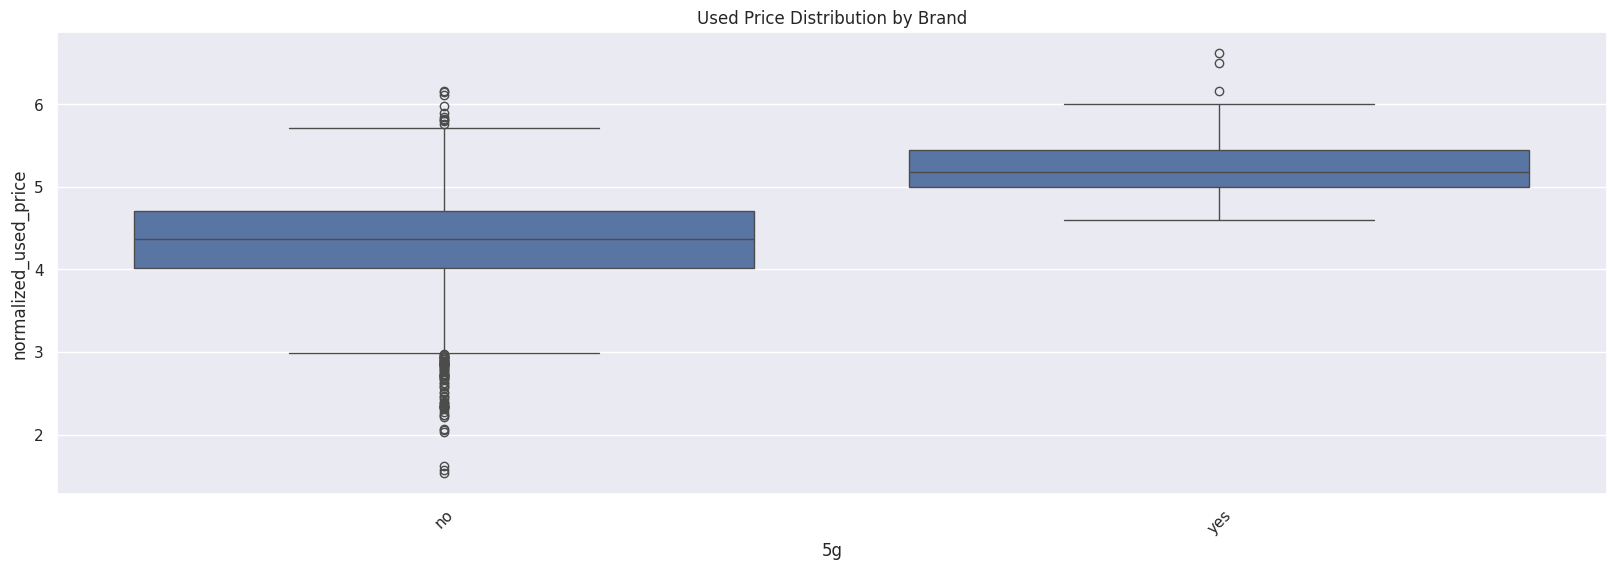

In [38]:
plt.figure(figsize=(20,6))
sns.boxplot(x="5g", y="normalized_used_price", data=df)
plt.xticks(rotation=45)
plt.title("Used Price Distribution by Brand")
plt.show()

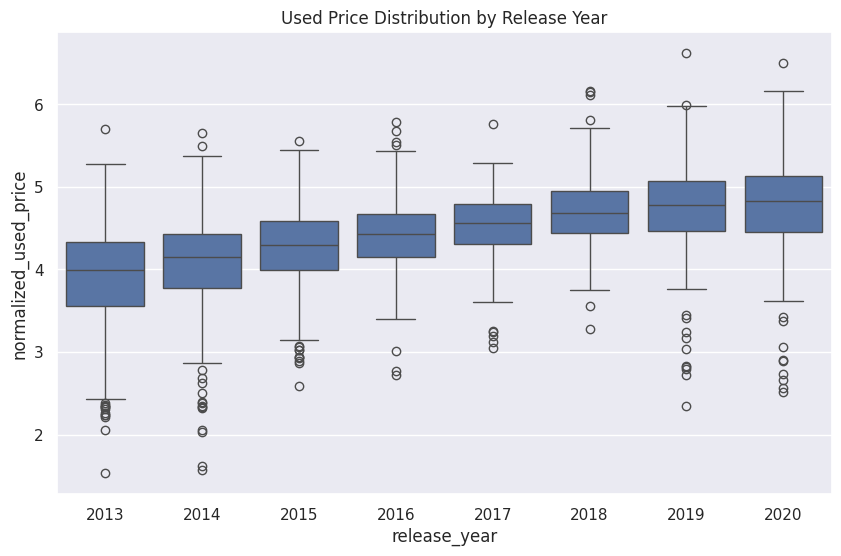

In [34]:
#Release Year vs Used Price
plt.figure(figsize=(10,6))
sns.boxplot(x="release_year", y="normalized_used_price", data=df)
plt.title("Used Price Distribution by Release Year")
plt.show()

*  Price has been increasing yearly.





What does the distribution of normalized used device prices look like?

**Central Tendency**

    Mean: 4.36

    Median (50%): 4.40

    The mean ≈ median → distribution is close to symmetric.

**Spread**

    Standard deviation: 0.59 → relatively tight spread.

    Most prices fall between 4.03 (25%) and 4.75 (75%).

    Range: 1.54 (min) → 6.62 (max).

**Shape**

    Since Q3 (4.75) is close to the max (6.62), we see a slight right skew (some higher-priced outliers).

    Lower bound (1.53) also shows a few very low-value devices.

**Outliers**

  High-priced outliers (~6.6) → represent premium newer models that retain value.

  Low-priced outliers (~1.5–2.0) → represent old or heavily used devices.

**Summary Statement:**
“The normalized used device prices are concentrated around 4.3–4.4, with most devices priced between 4.0 and 4.7. The distribution is fairly symmetric with a slight right skew, due to a few high-priced devices that retain value. Some extreme low and high outliers represent very old or premium models.”

In [44]:
data['brand_name'].value_counts()
android_percent = (data['os'] == 'Android').mean() * 100
print(f"Android devices: {android_percent:.2f}%")

Android devices: 93.05%


Q : What percentage of the used device market is dominated by Android devices?

We can calculate that directly:

Total devices: 3454

Android devices: 3214

Percentage of Android devices = (3214/3454)  × 100 = **93.05% (approx)**

In [45]:
brand_ram = data.groupby('brand_name')['ram'].mean().sort_values(ascending=False)
print(brand_ram)

brand_name
OnePlus       6.363636
Oppo          4.961240
Vivo          4.756410
Huawei        4.655378
Honor         4.603448
Xiaomi        4.583333
Google        4.533333
Meizu         4.451613
Samsung       4.199413
Realme        4.195122
Sony          4.069767
Asus          4.049180
ZTE           4.023214
Microsoft     4.000000
XOLO          4.000000
HTC           4.000000
Apple         4.000000
Panasonic     4.000000
Coolpad       3.954545
Motorola      3.943396
LG            3.936567
Gionee        3.933036
Acer          3.901961
Lenovo        3.885965
BlackBerry    3.829545
Others        3.777888
Spice         3.750000
Micromax      3.679487
Alcatel       3.407025
Karbonn       3.353448
Lava          3.277778
Infinix       2.600000
Nokia         2.420294
Celkon        1.613636
Name: ram, dtype: float64


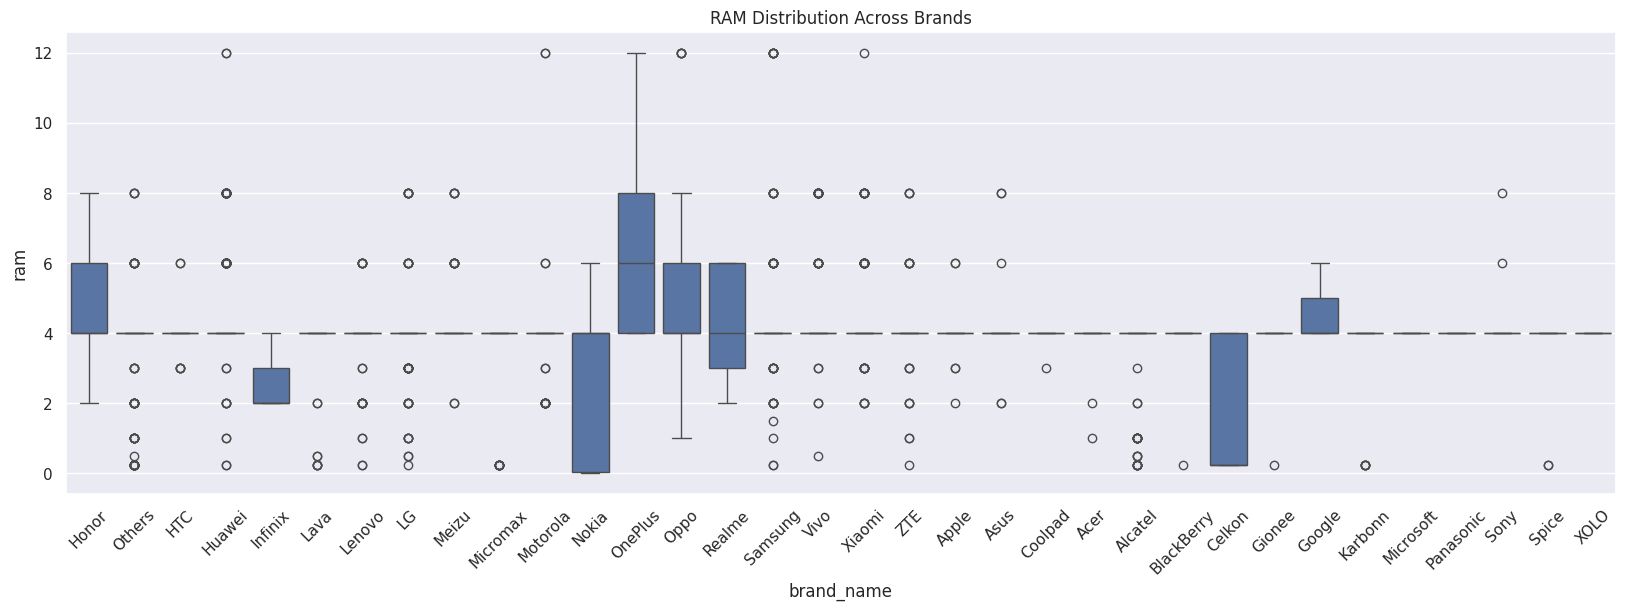

In [47]:
# Boxplot for RAM vs Brand
plt.figure(figsize=(20,6))
sns.boxplot(x='brand_name', y='ram', data=data)
plt.xticks(rotation=45)
plt.title('RAM Distribution Across Brands')
plt.show()

**Q: The amount of RAM is important for the smooth functioning of a device. How does the amount of RAM vary with the brand?**

Ans:

**High-RAM Brands**

OnePlus: 6.36 GB

Oppo: 4.96 GB

Vivo: 4.76 GB

Huawei: 4.66 GB

**Moderate-RAM Brands**

Brands like Xiaomi (4.58 GB), Google (4.53 GB), Samsung (4.20 GB), and Sony/Asus/Realme (4.0–4.2 GB) fall in the mid-range.

Devices from these brands are generally adequate for normal multitasking and day-to-day use.

**Insight:**

There is a clear correlation between brand positioning and RAM:

Premium brands → Higher RAM → Better multitasking.

Budget brands → Lower RAM → Basic functionality.

For smooth device performance, brands offering ≥4 GB RAM are generally better.

**A large battery often increases a device's weight, making it feel uncomfortable in the hands. How does the weight vary for phones and tablets offering large batteries (more than 4500 mAh)?**

In [51]:
large_battery = data[data['battery'] > 4500]

weight_stats = large_battery['weight'].describe()
print(weight_stats)

count    341.000000
mean     332.275660
std      155.501832
min      118.000000
25%      198.000000
50%      300.000000
75%      467.000000
max      855.000000
Name: weight, dtype: float64


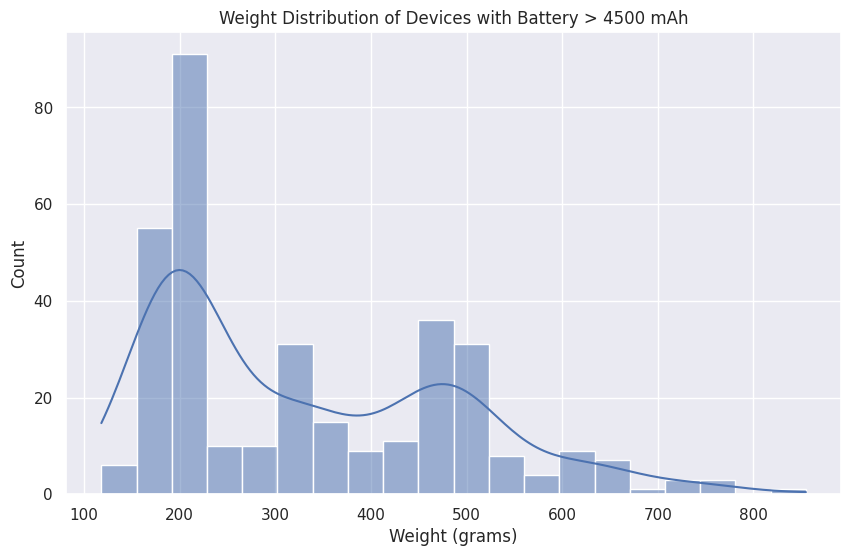

In [52]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.histplot(large_battery['weight'], bins=20, kde=True)
plt.title('Weight Distribution of Devices with Battery > 4500 mAh')
plt.xlabel('Weight (grams)')
plt.ylabel('Count')
plt.show()

Phones with large batteries are usually 200–467 g, heavier than typical phones, making them feel bulkier.

Tablets with large batteries push the upper range (up to 855 g).

Overall, larger batteries increase device weight, and there is considerable variation depending on device type and design.

**Q: Bigger screens are desirable for entertainment purposes as they offer a better viewing experience. How many phones and tablets are available across different brands with a screen size larger than 6 inches?**

In [54]:
large_screen = data[data['screen_size'] > 6]
# Count of large-screen devices per brand
brand_counts = large_screen['brand_name'].value_counts()
print(brand_counts)

brand_name
Others        479
Samsung       334
Huawei        251
LG            197
Lenovo        171
ZTE           140
Xiaomi        132
Oppo          129
Asus          122
Vivo          117
Honor         116
Alcatel       115
HTC           110
Micromax      108
Motorola      106
Sony           86
Nokia          72
Meizu          62
Gionee         56
Acer           51
XOLO           49
Panasonic      47
Realme         41
Apple          39
Lava           36
Spice          30
Karbonn        29
Celkon         25
Microsoft      22
OnePlus        22
Coolpad        22
BlackBerry     21
Google         15
Infinix        10
Name: count, dtype: int64


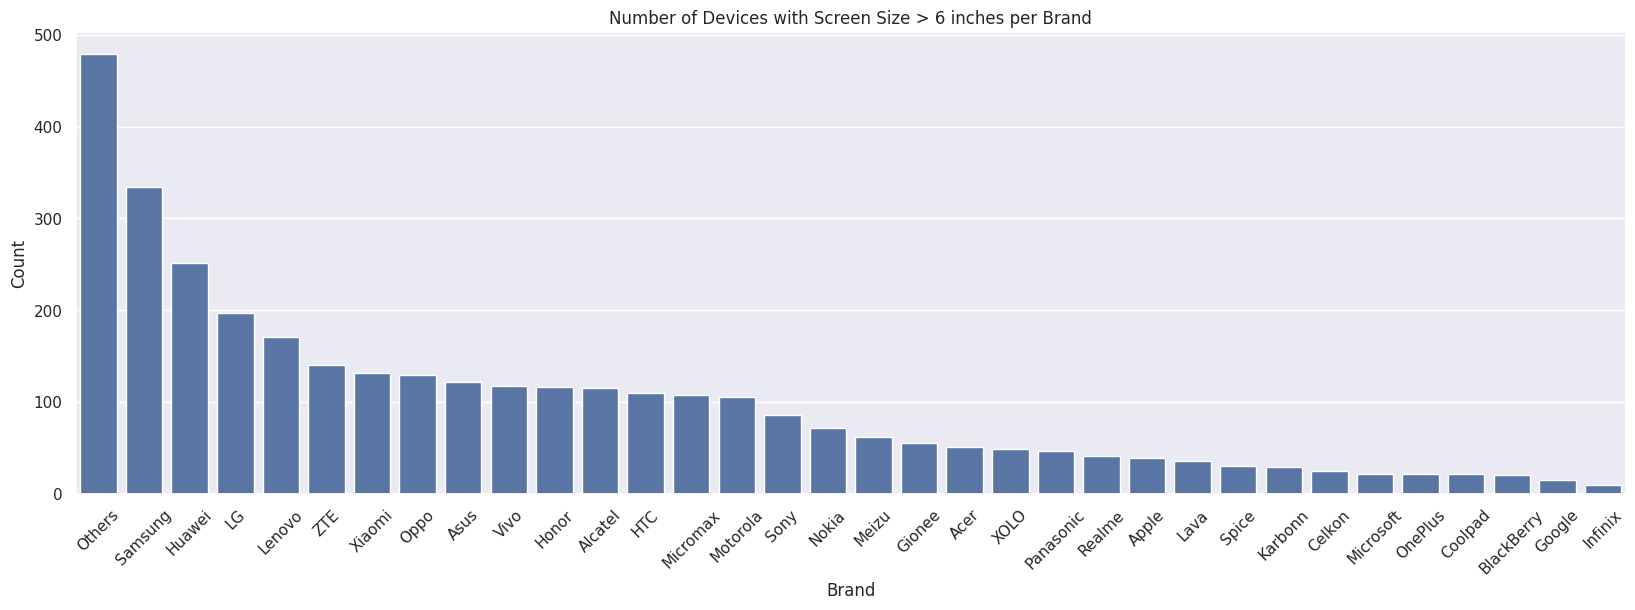

In [57]:
plt.figure(figsize=(20,6))
sns.barplot(x=brand_counts.index, y=brand_counts.values)
plt.xticks(rotation=45)
plt.title('Number of Devices with Screen Size > 6 inches per Brand')
plt.ylabel('Count')
plt.xlabel('Brand')
plt.show()

**Insights**

Brands like **Samsung, Huawei, and LG** dominate the large-screen market.

Most tablets are likely included in “Others” or brands with moderate counts.

Users who prefer screens >6 inches have plenty of options among mainstream brands, especially Samsung and Huawei.

**Q : A lot of devices nowadays offer great selfie cameras, allowing us to capture our favorite moments with loved ones. What is the distribution of devices offering greater than 8MP selfie cameras across brands?**

In [59]:
# Filter devices with selfie camera > 8 MP
high_selfie = data[data['selfie_camera_mp'] > 8]
brand_selfie_counts = high_selfie['brand_name'].value_counts()
print(brand_selfie_counts)

brand_name
Huawei        87
Vivo          78
Oppo          75
Xiaomi        63
Samsung       57
Honor         41
Others        34
LG            32
Motorola      26
Meizu         24
ZTE           20
HTC           20
Realme        18
OnePlus       18
Sony          14
Lenovo        14
Nokia         10
Asus           6
Infinix        4
Gionee         4
Coolpad        3
Micromax       2
BlackBerry     2
Panasonic      2
Acer           1
Name: count, dtype: int64


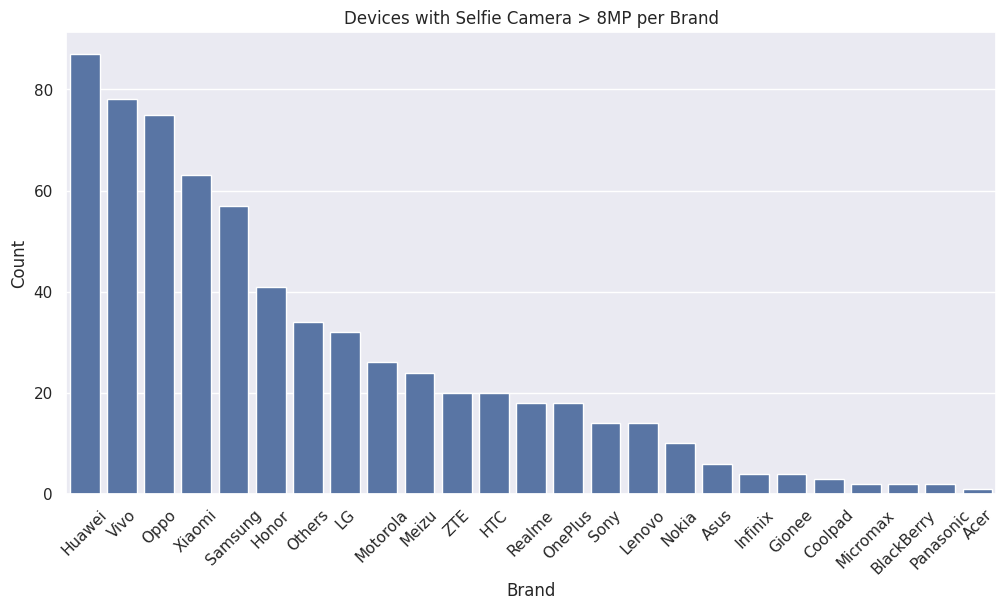

In [60]:
plt.figure(figsize=(12,6))
sns.barplot(x=brand_selfie_counts.index, y=brand_selfie_counts.values)
plt.xticks(rotation=45)
plt.title('Devices with Selfie Camera > 8MP per Brand')
plt.xlabel('Brand')
plt.ylabel('Count')
plt.show()

**Insight**

Premium and selfie-focused brands like **Huawei, Vivo, Oppo, and Xiaomi** dominate the market for high-resolution front cameras.

Users seeking >8MP selfies will have the widest options among these brands.

Budget and niche brands offer very few devices with high-resolution selfie cameras.

Q: **Which attributes are highly correlated with the normalized price of a used device?**

In [61]:
# Select numeric columns
numeric_cols = ['screen_size', 'main_camera_mp', 'selfie_camera_mp',
                'int_memory', 'ram', 'battery', 'weight',
                'release_year', 'days_used', 'normalized_new_price',
                'normalized_used_price']

corr_matrix = data[numeric_cols].corr()

In [62]:
# Correlation with normalized_used_price
corr_with_price = corr_matrix['normalized_used_price'].sort_values(ascending=False)
print(corr_with_price)

normalized_used_price    1.000000
normalized_new_price     0.834496
screen_size              0.614785
battery                  0.613619
selfie_camera_mp         0.608074
main_camera_mp           0.587302
ram                      0.520289
release_year             0.509790
weight                   0.382354
int_memory               0.190993
days_used               -0.358264
Name: normalized_used_price, dtype: float64


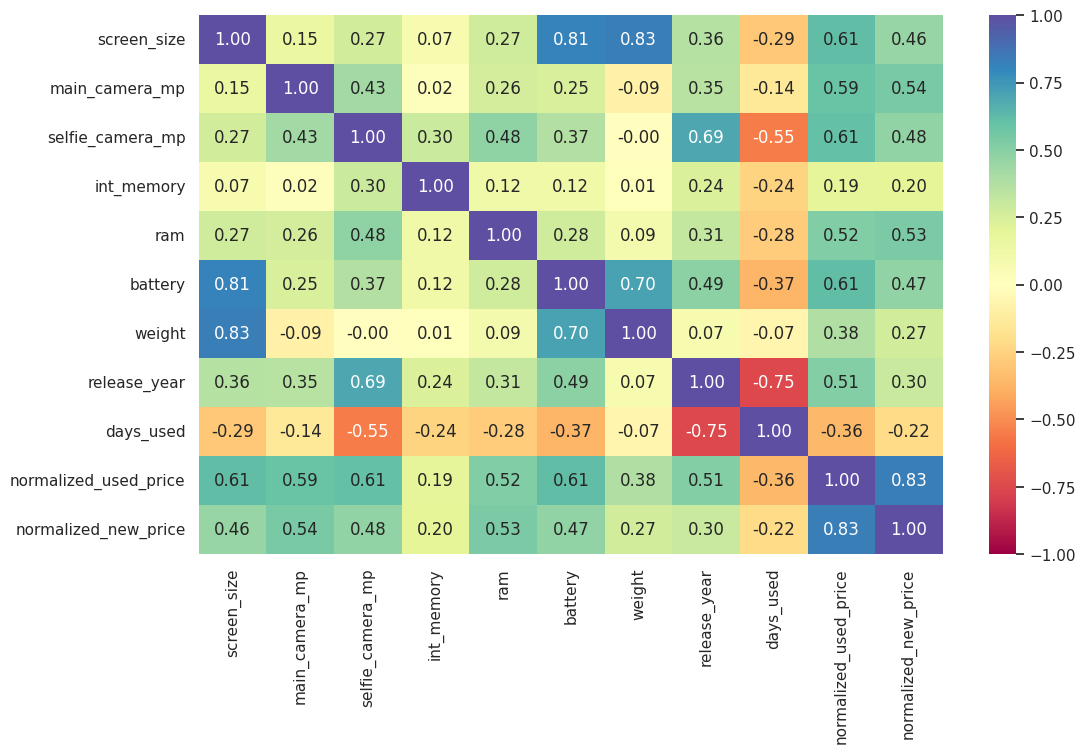

In [63]:
plt.figure(figsize=(12, 7))
sns.heatmap(
    df[num_cols].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral"
)
plt.show()

**Top Positive**

Based on data we got we can summarized below:

* **Normalized New Price (0.83)** – The higher the original price, the higher the resale value.

* **Screen Size (0.61)** – Larger screens slightly increase used device value.

* **Battery Capacity (0.61)** – Bigger batteries add to the resale price.

* **Selfie Camera MP (0.61) & Main Camera MP (0.59)** – Better cameras make devices more desirable.

* **RAM (0.52)** – More RAM increases usability and resale value.

* **Release Year (0.51)** – Newer devices fetch higher used prices.

**Moderate Positive**

* **Weight (0.38)** – Slight effect, heavier devices may indicate tablets or premium models.

* **Internal Memory** (0.19) – Small effect on resale value.

**Negative Influencer**

* **Days Used (-0.36)** – Longer usage reduces resale value.

**Summary Insight**

The most important factors for used device value are original price, screen size, battery, camera quality, RAM, and release year, while heavy usage lowers price. Storage and weight have minor effects.

**Let's check the variation in the normalized_used_price with some of the categorical columns in the data.**

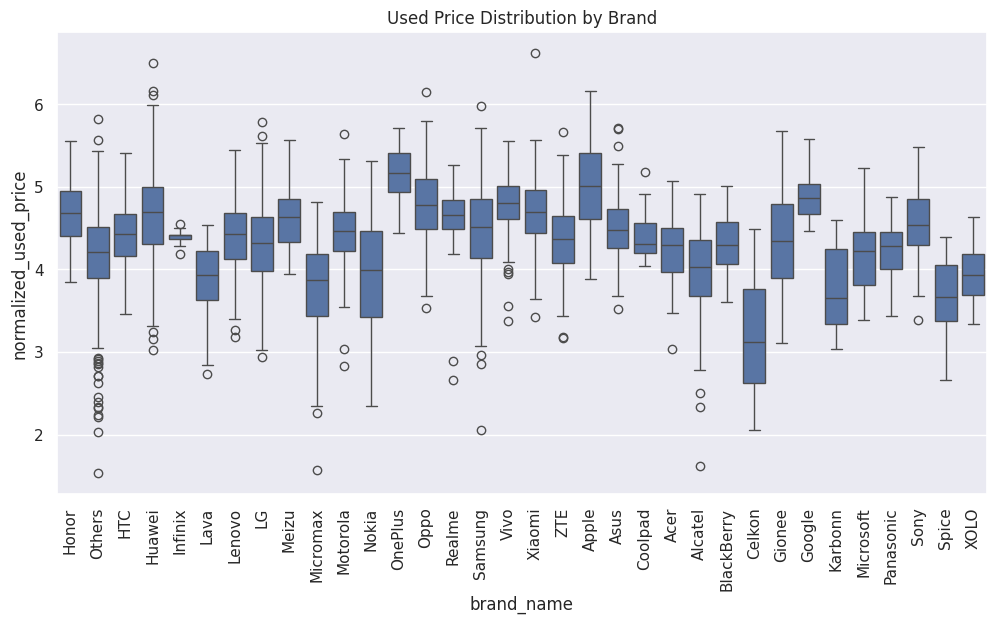

In [66]:
plt.figure(figsize=(12,6))
sns.boxplot(x='brand_name', y='normalized_used_price', data=data)
plt.xticks(rotation=90)
plt.title('Used Price Distribution by Brand')
plt.show()

* normalized_used_price for onePlus is the highest in general, while Apple ans samsung are in mid range.


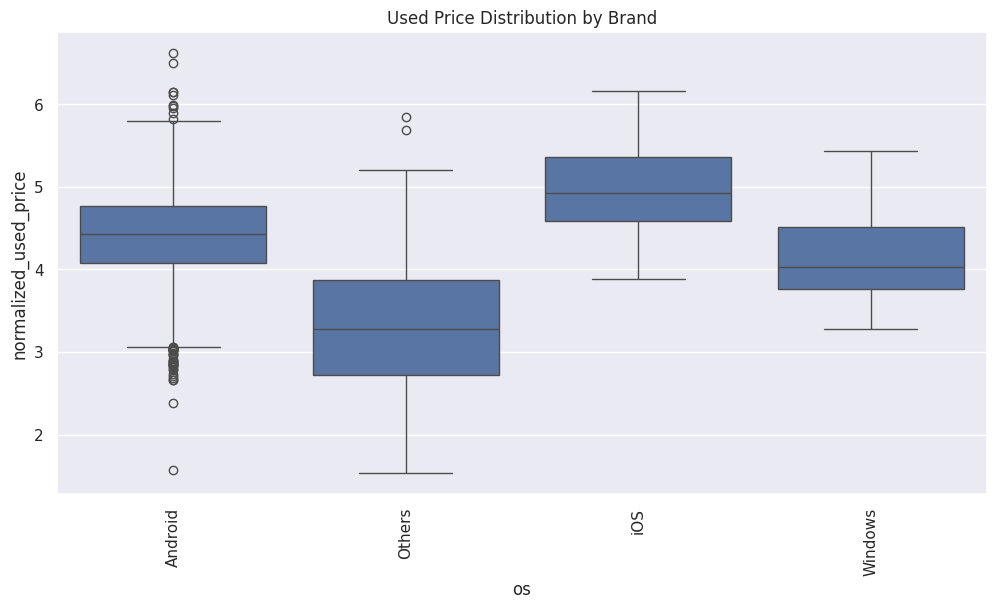

In [67]:
plt.figure(figsize=(12,6))
sns.boxplot(x='os', y='normalized_used_price', data=data)
plt.xticks(rotation=90)
plt.title('Used Price Distribution by Brand')
plt.show()

normalized_used_price is highest for ios in terms of OS.

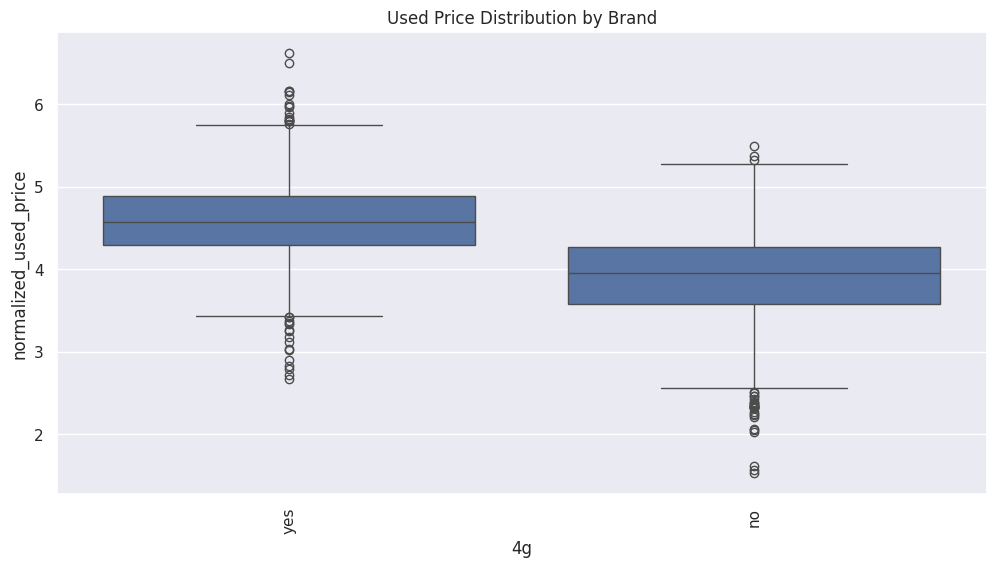

In [110]:
plt.figure(figsize=(12,6))
sns.boxplot(x='4g', y='normalized_used_price', data=data)
plt.xticks(rotation=90)
plt.title('Used Price Distribution by Brand')
plt.show()

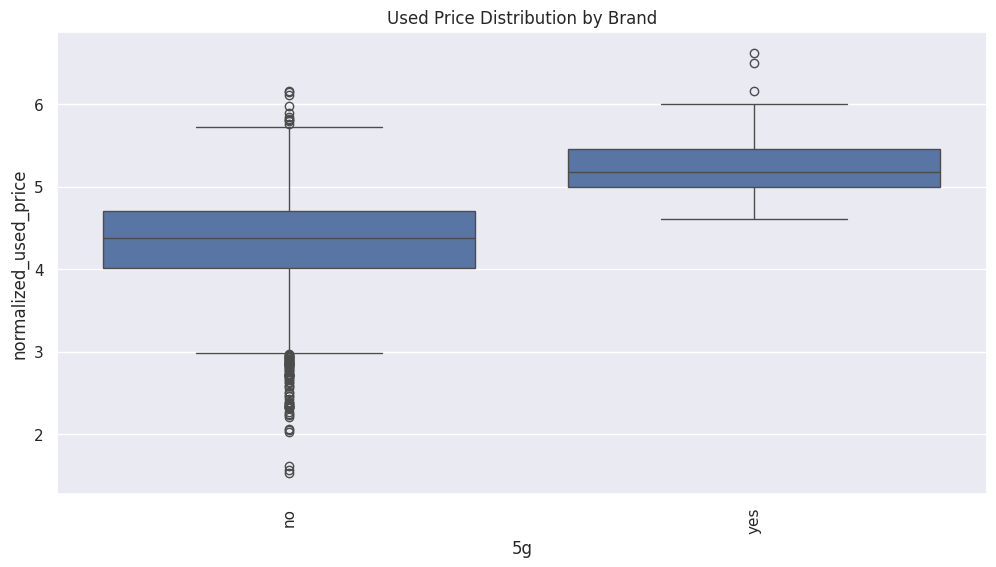

In [69]:
plt.figure(figsize=(12,6))
sns.boxplot(x='5g', y='normalized_used_price', data=data)
plt.xticks(rotation=90)
plt.title('Used Price Distribution by Brand')
plt.show()

## Data Preprocessing

- Missing value treatment
- Feature engineering (if needed)
- Outlier detection and treatment (if needed)
- Preparing data for modeling
- Any other preprocessing steps (if needed)

In [161]:
df1.isnull().sum()

,0
brand_name,0
os,0
screen_size,0
4g,0
5g,0
main_camera_mp,0
selfie_camera_mp,0
int_memory,0
ram,0
battery,0


Based on the above query there is not much data is missing.

main_camera_mp: 179 missing

selfie_camera_mp : 2 missing

int_memory : 4 missing

ram : 4 missing

battery : 6 missing

weight : 7 missing


**After this step:**

* All missing values will be imputed with median values.

* Dataset will be complete with no missing entries.

In [162]:
# Fill numerical missing values with median
num_cols = ['main_camera_mp', 'selfie_camera_mp', 'int_memory', 'ram', 'battery', 'weight']
df1 = df.copy()
for col in num_cols:
    df1[col].fillna(df1[col].median(), inplace=True)

# Check again
print(df1.isnull().sum())

brand_name               0
os                       0
screen_size              0
4g                       0
5g                       0
main_camera_mp           0
selfie_camera_mp         0
int_memory               0
ram                      0
battery                  0
weight                   0
release_year             0
days_used                0
normalized_used_price    0
normalized_new_price     0
dtype: int64


/tmp/ipython-input-1862926155.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df1[col].fillna(df1[col].median(), inplace=True)


**Feature engineering**

* Let's create a new feature as device_age_years (This captures how “old” a device really is).
* We will drop the original columns once the new feature is create.

**Device Age**

In [163]:
#Instead of just using release_year and days_used separately, create a new feature:
df1['device_age_years'] = (2025 - df1['release_year']) + (df1['days_used'] / 365)
df1.drop(["release_year", "days_used"], axis=1, inplace=True)
df1.head()

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,normalized_used_price,normalized_new_price,device_age_years
0,Honor,Android,14.50,yes,no,13.0,5.0,64.0,3.0,3020.0,146.0,4.307572,4.715100,5.361963
1,Honor,Android,17.30,yes,yes,13.0,16.0,128.0,8.0,4300.0,213.0,5.162097,5.519018,5.890411
2,Honor,Android,16.69,yes,yes,13.0,8.0,128.0,8.0,4200.0,213.0,5.111084,5.884631,5.443836
3,Honor,Android,25.50,yes,yes,13.0,8.0,64.0,6.0,7250.0,480.0,5.135387,5.630961,5.945205
4,Honor,Android,15.32,yes,no,13.0,8.0,64.0,3.0,5000.0,185.0,4.389995,4.947837,5.802740


**Memory Features**

In [113]:
#Combine ram and int_memory to create total memory capacity:

df1['total_memory'] = df1['ram'] + df1['int_memory']
df1.head()

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,normalized_used_price,normalized_new_price,device_age_years,total_memory
0,Honor,Android,14.50,yes,no,13.0,5.0,64.0,3.0,3020.0,146.0,4.307572,4.715100,5.347945,67.0
1,Honor,Android,17.30,yes,yes,13.0,16.0,128.0,8.0,4300.0,213.0,5.162097,5.519018,5.890411,136.0
2,Honor,Android,16.69,yes,yes,13.0,8.0,128.0,8.0,4200.0,213.0,5.111084,5.884631,5.443836,136.0
3,Honor,Android,25.50,yes,yes,13.0,8.0,64.0,6.0,7250.0,480.0,5.135387,5.630961,5.945205,70.0
4,Honor,Android,15.32,yes,no,13.0,8.0,64.0,3.0,5000.0,185.0,4.389995,4.947837,5.802740,67.0


**Flag Features**


In [164]:
#Binary flags for easy classification:

df1['is_5g'] = df1['5g'].map({'yes':1, 'no':0})
df1['is_4g'] = df1['4g'].map({'yes':1, 'no':0})
df1['is_tablet'] = df1['screen_size'].apply(lambda x: 1 if x >= 7 else 0)
df1.head()

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,normalized_used_price,normalized_new_price,device_age_years,is_5g,is_4g,is_tablet
0,Honor,Android,14.50,yes,no,13.0,5.0,64.0,3.0,3020.0,146.0,4.307572,4.715100,5.361963,0,1,1
1,Honor,Android,17.30,yes,yes,13.0,16.0,128.0,8.0,4300.0,213.0,5.162097,5.519018,5.890411,1,1,1
2,Honor,Android,16.69,yes,yes,13.0,8.0,128.0,8.0,4200.0,213.0,5.111084,5.884631,5.443836,1,1,1
3,Honor,Android,25.50,yes,yes,13.0,8.0,64.0,6.0,7250.0,480.0,5.135387,5.630961,5.945205,1,1,1
4,Honor,Android,15.32,yes,no,13.0,8.0,64.0,3.0,5000.0,185.0,4.389995,4.947837,5.802740,0,1,1


We will drop the columns 4g and 5g as they contain a text and we created the new column is_4g and is_5g as numeric representation, and can be excluded from modeling

**Outlier detection and treatment (if needed)**



ValueError: num must be an integer with 1 <= num <= 9, not 10

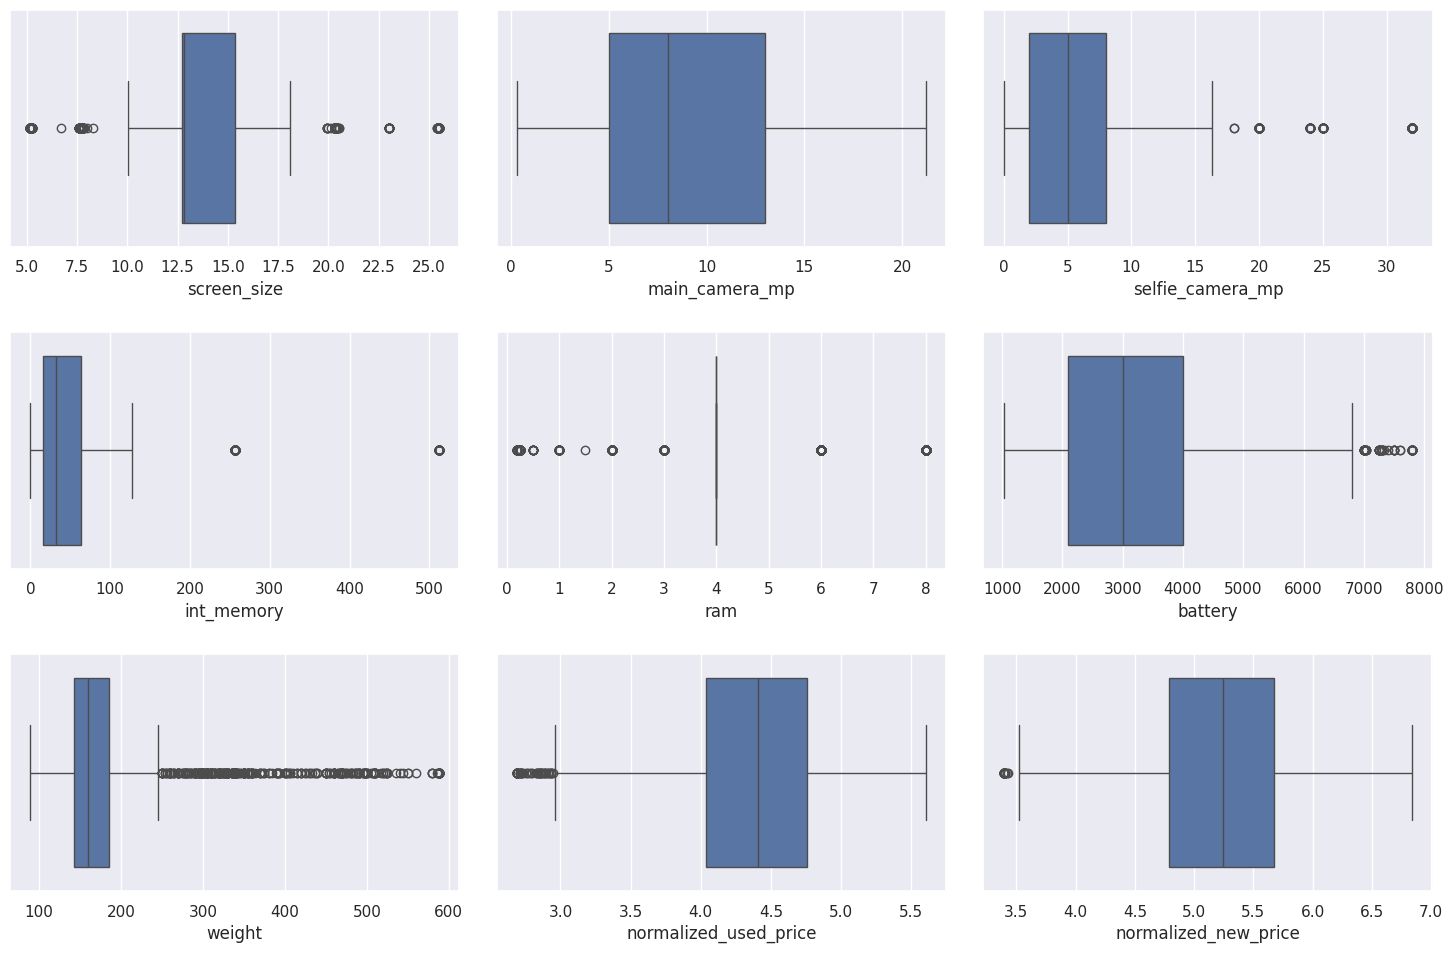

In [165]:

num_cols = df1.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(15, 10))

for i, variable in enumerate(num_cols):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(data=df1, x=variable)
    plt.tight_layout(pad=2)

plt.show()

* There are quite a few outliers in the data.
* However, we will not treat them as they are proper values
* We will drop the columns 4g and 5g as they contain a text, and can be excluded from modeling

In [166]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3454 entries, 0 to 3453
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   brand_name             3454 non-null   object 
 1   os                     3454 non-null   object 
 2   screen_size            3454 non-null   float64
 3   4g                     3454 non-null   object 
 4   5g                     3454 non-null   object 
 5   main_camera_mp         3454 non-null   float64
 6   selfie_camera_mp       3454 non-null   float64
 7   int_memory             3454 non-null   float64
 8   ram                    3454 non-null   float64
 9   battery                3454 non-null   float64
 10  weight                 3454 non-null   float64
 11  normalized_used_price  3454 non-null   float64
 12  normalized_new_price   3454 non-null   float64
 13  device_age_years       3454 non-null   float64
 14  is_5g                  3454 non-null   int64  
 15  is_4

In [167]:
df1.drop(["4g", "5g"], axis=1, inplace=True)
df1.head()

,brand_name,os,screen_size,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,normalized_used_price,normalized_new_price,device_age_years,is_5g,is_4g,is_tablet
0,Honor,Android,14.50,13.0,5.0,64.0,3.0,3020.0,146.0,4.307572,4.715100,5.361963,0,1,1
1,Honor,Android,17.30,13.0,16.0,128.0,8.0,4300.0,213.0,5.162097,5.519018,5.890411,1,1,1
2,Honor,Android,16.69,13.0,8.0,128.0,8.0,4200.0,213.0,5.111084,5.884631,5.443836,1,1,1
3,Honor,Android,25.50,13.0,8.0,64.0,6.0,7250.0,480.0,5.135387,5.630961,5.945205,1,1,1
4,Honor,Android,15.32,13.0,8.0,64.0,3.0,5000.0,185.0,4.389995,4.947837,5.802740,0,1,1


In [168]:
# List of numeric columns to check for outliers
num_cols = ['screen_size', 'main_camera_mp', 'selfie_camera_mp',
            'int_memory', 'ram', 'battery', 'weight',
            'days_used', 'normalized_used_price', 'normalized_new_price']

# Function to cap outliers
def cap_outliers(df1, columns):
    for col in columns:
        Q1 = df1[col].quantile(0.25)
        Q3 = df1[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        #cap at 1st and 99th percentile to avoid extreme distortion
        lower_cap = df1[col].quantile(0.01)
        upper_cap = df1[col].quantile(0.99)

        df[col] = df1[col].clip(lower=lower_cap, upper=upper_cap)
    return df1

# Apply the function
data = cap_outliers(data, num_cols)

#summary statistics after capping
print(data[num_cols].describe())

       screen_size  main_camera_mp  selfie_camera_mp   int_memory  \
count  3454.000000     3275.000000       3452.000000  3450.000000   
mean     13.694679        9.405863          6.554229    53.386087   
std       3.734539        4.569172          6.970372    74.325975   
min       5.180000        0.300000          0.000000     0.100000   
25%      12.700000        5.000000          2.000000    16.000000   
50%      12.830000        8.000000          5.000000    32.000000   
75%      15.340000       13.000000          8.000000    64.000000   
max      25.500000       21.200000         32.000000   512.000000   

               ram      battery       weight    days_used  \
count  3450.000000  3448.000000  3447.000000  3454.000000   
mean      4.016398  3125.495244   182.013464   675.033932   
std       1.266908  1260.142396    83.983031   248.032963   
min       0.137800  1024.700000    89.246000   131.120000   
25%       4.000000  2100.000000   142.000000   533.500000   
50%       4.

**Preparing data for modeling**

* We want to predict the normalized_used_price.
* Before we proceed to build a model, we'll have to encode categorical features
* We'll split the data into train and test to be able to evaluate the model that we build on the train data
* We will build a Linear Regression model using the train data and then check it's performance


In [169]:
X = df1.drop(["normalized_used_price"], axis=1)
y = df1["normalized_used_price"]

print(X.head())
print(y.head())

  brand_name       os  screen_size  main_camera_mp  selfie_camera_mp  \
0      Honor  Android        14.50            13.0               5.0   
1      Honor  Android        17.30            13.0              16.0   
2      Honor  Android        16.69            13.0               8.0   
3      Honor  Android        25.50            13.0               8.0   
4      Honor  Android        15.32            13.0               8.0   

   int_memory  ram  battery  weight  normalized_new_price  device_age_years  \
0        64.0  3.0   3020.0   146.0              4.715100          5.361963   
1       128.0  8.0   4300.0   213.0              5.519018          5.890411   
2       128.0  8.0   4200.0   213.0              5.884631          5.443836   
3        64.0  6.0   7250.0   480.0              5.630961          5.945205   
4        64.0  3.0   5000.0   185.0              4.947837          5.802740   

   is_5g  is_4g  is_tablet  
0      0      1          1  
1      1      1          1  
2    

In [170]:
# let's add the intercept to data
X = sm.add_constant(X)

In [171]:
# creating dummy variables
X = pd.get_dummies(
    X,
    columns=X.select_dtypes(include=["object", "category"]).columns.tolist(),
    drop_first=True
)
X.head()

,const,screen_size,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,normalized_new_price,device_age_years,...,brand_name_Samsung,brand_name_Sony,brand_name_Spice,brand_name_Vivo,brand_name_XOLO,brand_name_Xiaomi,brand_name_ZTE,os_Others,os_Windows,os_iOS
0,1.0,14.50,13.0,5.0,64.0,3.0,3020.0,146.0,4.715100,5.361963,...,False,False,False,False,False,False,False,False,False,False
1,1.0,17.30,13.0,16.0,128.0,8.0,4300.0,213.0,5.519018,5.890411,...,False,False,False,False,False,False,False,False,False,False
2,1.0,16.69,13.0,8.0,128.0,8.0,4200.0,213.0,5.884631,5.443836,...,False,False,False,False,False,False,False,False,False,False
3,1.0,25.50,13.0,8.0,64.0,6.0,7250.0,480.0,5.630961,5.945205,...,False,False,False,False,False,False,False,False,False,False
4,1.0,15.32,13.0,8.0,64.0,3.0,5000.0,185.0,4.947837,5.802740,...,False,False,False,False,False,False,False,False,False,False


In [172]:
# converting the input attributes into float type for modeling
X = X.astype(float)
X.head()

,const,screen_size,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,normalized_new_price,device_age_years,...,brand_name_Samsung,brand_name_Sony,brand_name_Spice,brand_name_Vivo,brand_name_XOLO,brand_name_Xiaomi,brand_name_ZTE,os_Others,os_Windows,os_iOS
0,1.0,14.50,13.0,5.0,64.0,3.0,3020.0,146.0,4.715100,5.361963,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,17.30,13.0,16.0,128.0,8.0,4300.0,213.0,5.519018,5.890411,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,16.69,13.0,8.0,128.0,8.0,4200.0,213.0,5.884631,5.443836,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,25.50,13.0,8.0,64.0,6.0,7250.0,480.0,5.630961,5.945205,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,15.32,13.0,8.0,64.0,3.0,5000.0,185.0,4.947837,5.802740,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [173]:
# splitting the data in 70:30 ratio for train to test data

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

In [174]:
print("Number of rows in train data =", x_train.shape[0])
print("Number of rows in test data =", x_test.shape[0])

Number of rows in train data = 2417
Number of rows in test data = 1037


## EDA

- It is a good idea to explore the data once again after manipulating it.

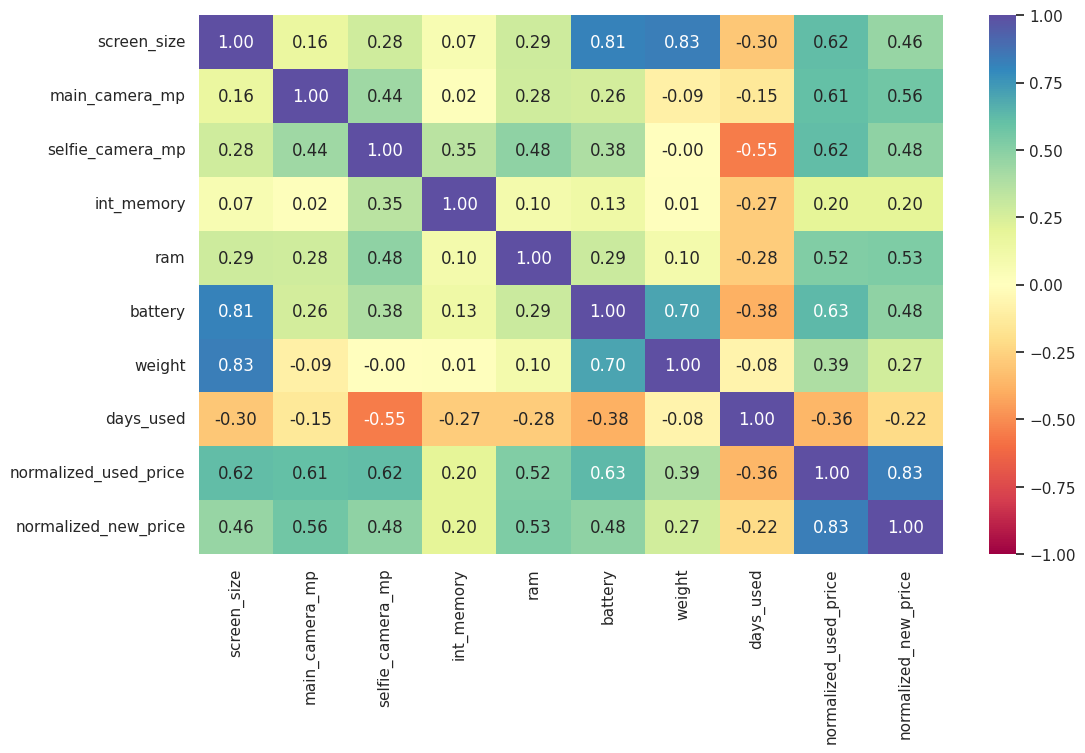

In [175]:
plt.figure(figsize=(12, 7))
sns.heatmap(
    df[num_cols].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral"
)
plt.show()

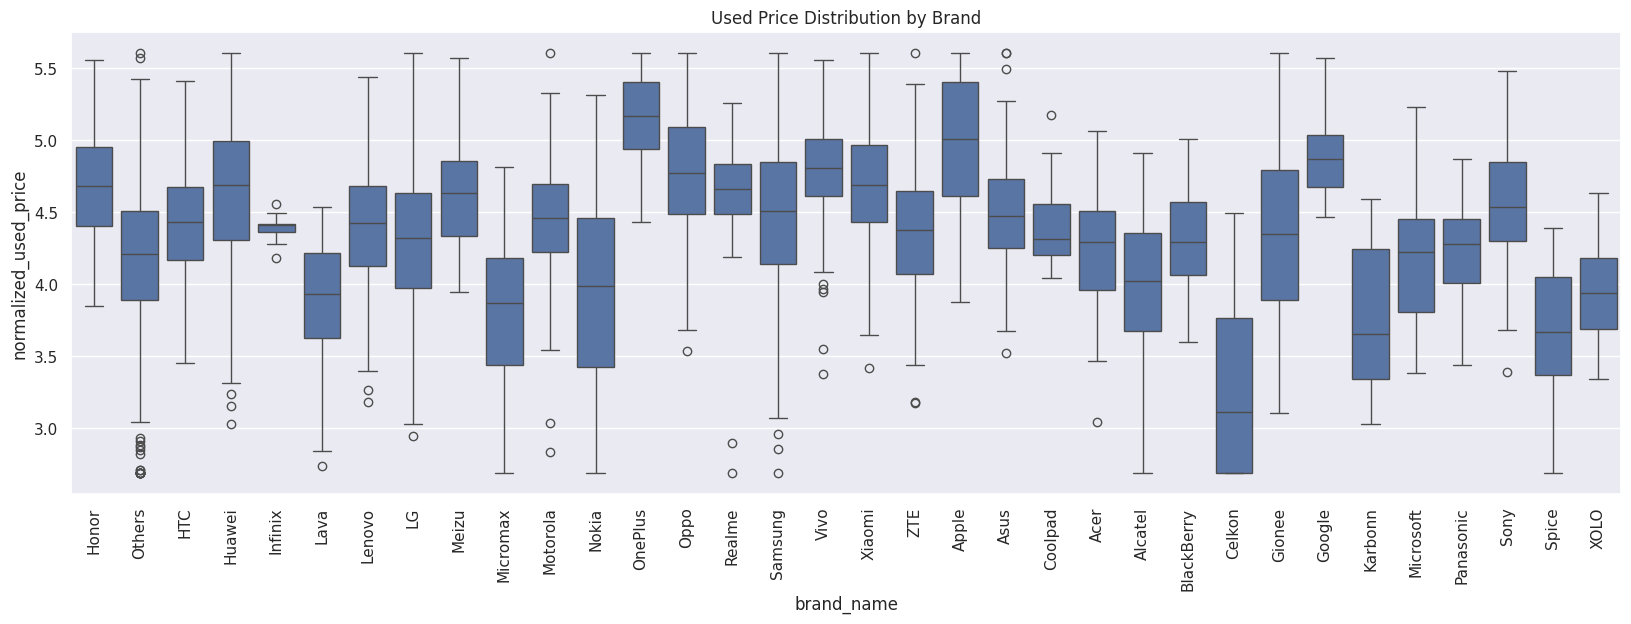

In [176]:
plt.figure(figsize=(20,6))
sns.boxplot(x='brand_name', y='normalized_used_price', data=data)
plt.xticks(rotation=90)
plt.title('Used Price Distribution by Brand')
plt.show()

## Model Building - Linear Regression

In [151]:
x_train = x_train.fillna(0)
y_train = y_train.fillna(0)

In [177]:
olsmodel = sm.OLS(y_train, x_train).fit()
print(olsmodel.summary())

                              OLS Regression Results                             
Dep. Variable:     normalized_used_price   R-squared:                       0.846
Model:                               OLS   Adj. R-squared:                  0.843
Method:                    Least Squares   F-statistic:                     270.6
Date:                   Mon, 22 Sep 2025   Prob (F-statistic):               0.00
Time:                           05:32:34   Log-Likelihood:                 204.91
No. Observations:                   2417   AIC:                            -311.8
Df Residuals:                       2368   BIC:                            -28.09
Df Model:                             48                                         
Covariance Type:               nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------


**Interpreting the Regression Results:**

**Adjusted. R-squared:** It reflects the fit of the model.

R-squared = 0.842 → 84.2% of variance in used price is explained by all predictors.

Adjusted R-squared = 0.839 → After accounting for the number of predictors, the model still explains ~83.9% of the variance.

- In our case, the value for adj. R-squared is **0.842**, which is good.


***const* coefficient**: It is the Y-intercept.

Interpretation

This means that the baseline predicted used price is -65.0355 when all predictors (screen size, RAM, battery, camera, brand, OS, etc.) are zero.

Practically, this negative value doesn’t have real-world meaning (since device specs like screen size or RAM can’t be zero).

The constant mainly serves as a reference point for the regression line, and all other coefficients represent how each feature changes the used price relative to this baseline.

**Coefficient of a predictor variable**: It represents the change in the output Y due to a change in the predictor variable (everything else held constant).
    - In our case, the coefficient of `normalized_new_price` is **0.4483**.

## Model Performance Check

Let's check the performance of the model using different metrics.

We will be using metric functions defined in sklearn for RMSE, MAE, and  R2 .

We will define a function to calculate MAPE and adjusted  R2 .

The mean absolute percentage error (MAPE) measures the accuracy of predictions as a percentage, and can be calculated as the average absolute percent error for each predicted value minus actual values divided by actual values. It works best if there are no extreme values in the data and none of the actual values are 0.
We will create a function which will print out all the above metrics in one go.

In [178]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute MAPE
def mape_score(targets, predictions):
    return np.mean(np.abs(targets - predictions) / targets) * 100


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mape_score(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

In [179]:
# checking model performance on train set (seen 70% data)
print("Training Performance\n")
olsmodel_train_perf = model_performance_regression(olsmodel, x_train, y_train)
olsmodel_train_perf

Training Performance



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,0.222303,0.175786,0.845779,0.842587,4.173064


In [180]:
# checking model performance on test set (seen 30% data)
print("Test Performance\n")
olsmodel_test_perf = model_performance_regression(olsmodel, x_test, y_test)
olsmodel_test_perf

Test Performance



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,0.22939,0.179185,0.843632,0.835869,4.26305


**Observations**

*  The training  **R2  is 0.84**, The model is not underfitting the training data

* The train and test RMSE and MAE are comparable, so the model is not overfitting either

* MAE suggests that the model can predict that On average, the predicted used price is off by 0.176 units from the actual price.

* Since your normalized price likely ranges roughly from 0 to 1, this is a small error, meaning the model’s predictions are quite close to actual values.

* MAPE of 4.17 On average, the model’s predicted used price is only about 4.17% off from the actual price.

This is very good for a regression model, indicating strong predictive accuracy.

## Checking Linear Regression Assumptions

- In order to make statistical inferences from a linear regression model, it is important to ensure that the assumptions of linear regression are satisfied.

We will be checking the following Linear Regression assumptions:

1. **No Multicollinearity**

2. **Linearity of variables**

3. **Independence of error terms**

4. **Normality of error terms**

5. **No Heteroscedasticity**

**TEST FOR MULTICOLLINEARITY**

In [182]:
from statsmodels.stats.outliers_influence import variance_inflation_factor


def checking_vif(predictors):
    vif = pd.DataFrame()
    vif["feature"] = predictors.columns

    # calculating VIF for each feature
    vif["VIF"] = [
        variance_inflation_factor(predictors.values, i)
        for i in range(len(predictors.columns))
    ]
    return vif

In [183]:
checking_vif(x_train)

,feature,VIF
0,const,342.243696
1,screen_size,8.381970
2,main_camera_mp,2.338597
3,selfie_camera_mp,2.874673
4,int_memory,1.494054
5,ram,2.287619
6,battery,4.217287
7,weight,6.677388
8,normalized_new_price,3.174908
9,device_age_years,3.499617


* There are multiple columns with very high VIF values, indicating presence of strong multicollinearity

* We will systematically drop numerical columns with VIF > 5

* We will ignore the VIF values for dummy variables and the constant (intercept)

**Removing Multicollinearity**

In [184]:
def treating_multicollinearity(predictors, target, high_vif_columns):
    """
    Checking the effect of dropping the columns showing high multicollinearity
    on model performance (adj. R-squared and RMSE)

    predictors: independent variables
    target: dependent variable
    high_vif_columns: columns having high VIF
    """
    # empty lists to store adj. R-squared and RMSE values
    adj_r2 = []
    rmse = []

    # build ols models by dropping one of the high VIF columns at a time
    # store the adjusted R-squared and RMSE in the lists defined previously
    for cols in high_vif_columns:
        # defining the new train set
        train = predictors.loc[:, ~predictors.columns.str.startswith(cols)]

        # create the model
        olsmodel = sm.OLS(target, train).fit()

        # adding adj. R-squared and RMSE to the lists
        adj_r2.append(olsmodel.rsquared_adj)
        rmse.append(np.sqrt(olsmodel.mse_resid))

    # creating a dataframe for the results
    temp = pd.DataFrame(
        {
            "col": high_vif_columns,
            "Adj. R-squared after_dropping col": adj_r2,
            "RMSE after dropping col": rmse,
        }
    ).sort_values(by="Adj. R-squared after_dropping col", ascending=False)
    temp.reset_index(drop=True, inplace=True)

    return temp

In [185]:
col_list = ["brand_name_Apple", "os_iOS"]

res = treating_multicollinearity(x_train, y_train, col_list)
res

,col,Adj. R-squared after_dropping col,RMSE after dropping col
0,os_iOS,0.842710,0.224550
1,brand_name_Apple,0.842684,0.224569


In [186]:
col_to_drop = "os_iOS"
x_train2 = x_train.loc[:, ~x_train.columns.str.startswith(col_to_drop)]
x_test2 = x_test.loc[:, ~x_test.columns.str.startswith(col_to_drop)]

# Check VIF now
vif = checking_vif(x_train2)
print("VIF after dropping ", col_to_drop)
vif

VIF after dropping  os_iOS


,feature,VIF
0,const,335.889843
1,screen_size,8.381946
2,main_camera_mp,2.334274
3,selfie_camera_mp,2.866074
4,int_memory,1.494006
5,ram,2.274084
6,battery,4.215683
7,weight,6.670692
8,normalized_new_price,3.174903
9,device_age_years,3.482665


In [187]:
col_list = ["brand_name_Apple", "brand_name_Others"]

res = treating_multicollinearity(x_train, y_train, col_list)
res

,col,Adj. R-squared after_dropping col,RMSE after dropping col
0,brand_name_Others,0.842718,0.224544
1,brand_name_Apple,0.842684,0.224569


In [188]:
col_to_drop = "brand_name_Others"
x_train2 = x_train.loc[:, ~x_train.columns.str.startswith(col_to_drop)]
x_test2 = x_test.loc[:, ~x_test.columns.str.startswith(col_to_drop)]

# Check VIF now
vif = checking_vif(x_train2)
print("VIF after dropping ", col_to_drop)
vif

VIF after dropping  brand_name_Others


,feature,VIF
0,const,263.674686
1,screen_size,8.345292
2,main_camera_mp,2.336467
3,selfie_camera_mp,2.874670
4,int_memory,1.493434
5,ram,2.286757
6,battery,4.217244
7,weight,6.661925
8,normalized_new_price,3.174904
9,device_age_years,3.495753


* We have dealt with multicollinearity in the data
* Let's rebuild the model using the updated set of predictors variables

In [189]:
olsmod1 = sm.OLS(y_train, x_train2).fit()
print(olsmod1.summary())

                              OLS Regression Results                             
Dep. Variable:     normalized_used_price   R-squared:                       0.846
Model:                               OLS   Adj. R-squared:                  0.843
Method:                    Least Squares   F-statistic:                     276.4
Date:                   Mon, 22 Sep 2025   Prob (F-statistic):               0.00
Time:                           05:58:36   Log-Likelihood:                 204.90
No. Observations:                   2417   AIC:                            -313.8
Df Residuals:                       2369   BIC:                            -35.86
Df Model:                             47                                         
Covariance Type:               nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------


**Interpreting the Regression Results:**

**Observations**


Adjusted R-squared has actually slightly increased (0.8426 → 0.843).

This indicates that dropping/adjusting multicollinear variables (like os_iOS) did not hurt model fit.

In fact, the model may have slightly improved in terms of explaining variance while reducing multicollinearity.

Conclusion: Adj. R-squared has not dropped; model fit remains strong.

**Dealing with high p-value variables**

In [190]:
# initial list of columns
predictors = x_train2.copy()
cols = predictors.columns.tolist()

# setting an initial max p-value
max_p_value = 1

while len(cols) > 0:
    # defining the train set
    x_train_aux = predictors[cols]

    # fitting the model
    model = sm.OLS(y_train, x_train_aux).fit()

    # getting the p-values and the maximum p-value
    p_values = model.pvalues
    max_p_value = max(p_values)

    # name of the variable with maximum p-value
    feature_with_p_max = p_values.idxmax()

    if max_p_value > 0.05:
        cols.remove(feature_with_p_max)
    else:
        break

selected_features = cols
print(selected_features)

['const', 'screen_size', 'main_camera_mp', 'selfie_camera_mp', 'ram', 'weight', 'normalized_new_price', 'device_age_years', 'is_4g', 'brand_name_OnePlus', 'brand_name_Realme', 'brand_name_Xiaomi']


In [191]:
x_train3 = x_train2[selected_features]
x_test3 = x_test2[selected_features]

In [192]:
olsmod2 = sm.OLS(y_train, x_train3).fit()
print(olsmod2.summary())

                              OLS Regression Results                             
Dep. Variable:     normalized_used_price   R-squared:                       0.843
Model:                               OLS   Adj. R-squared:                  0.843
Method:                    Least Squares   F-statistic:                     1177.
Date:                   Mon, 22 Sep 2025   Prob (F-statistic):               0.00
Time:                           06:05:39   Log-Likelihood:                 186.34
No. Observations:                   2417   AIC:                            -348.7
Df Residuals:                       2405   BIC:                            -279.2
Df Model:                             11                                         
Covariance Type:               nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
co

In [193]:
# checking model performance on train set (seen 70% data)
print("Training Performance\n")
olsmod2_train_perf = model_performance_regression(olsmod2, x_train3, y_train)
olsmod2_train_perf

Training Performance



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,0.224017,0.177705,0.843391,0.842609,4.220733


In [194]:
# checking model performance on test set (seen 30% data)
print("Test Performance\n")
olsmod2_test_perf = model_performance_regression(olsmod2, x_test3, y_test)
olsmod2_test_perf

Test Performance



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,0.227505,0.178144,0.846191,0.844389,4.236806


**Observations**

The model explains 84–85% of the variation in normalized used device prices R-squared = 0.846, Adj. R-squared = 0.844).

**Prediction Accuracy:**

RMSE 0.224 (train), 0.228 (test) => typical prediction error is low.

MAE 0.178 => on average, predictions deviate from actual prices by 0.178 units.

MAPE 4.2% => model predicts prices within 4% of the actual value, very accurate.

**TEST FOR LINEARITY AND INDEPENDENCE**

In [195]:
# let us create a dataframe with actual, fitted and residual values
df_pred = pd.DataFrame()

df_pred["Actual Values"] = y_train  # actual values
df_pred["Fitted Values"] = olsmod2.fittedvalues  # predicted values
df_pred["Residuals"] = olsmod2.resid  # residuals

df_pred.head()

,Actual Values,Fitted Values,Residuals
3026,4.087488,3.861279,0.226208
1525,4.448399,4.606466,-0.158067
1128,4.315353,4.304001,0.011351
3003,4.282068,4.241840,0.040229
2907,4.456438,4.498700,-0.042261


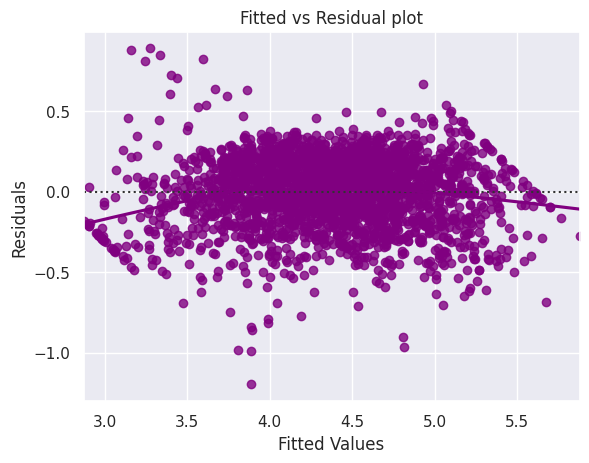

In [196]:
# let's plot the fitted values vs residuals

sns.residplot(
    data=df_pred, x="Fitted Values", y="Residuals", color="purple", lowess=True
)
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Fitted vs Residual plot")
plt.show()

* The residuals indicate that the model fits the data well, with no obvious bias or non-linearity in this small sample.

* A full residual plot with all data points will give a more complete picture of random scatter and homoscedasticity.

**TEST FOR NORMALITY**

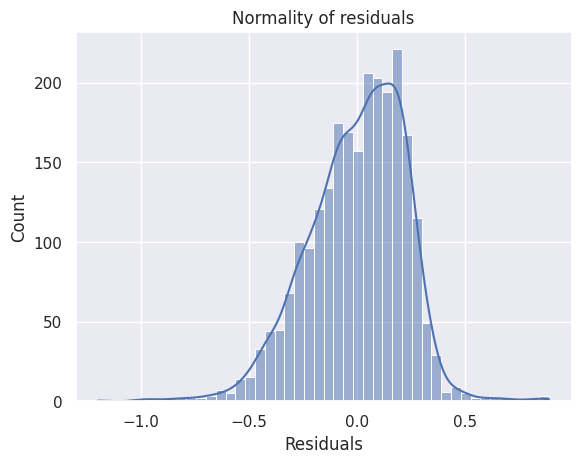

In [197]:
sns.histplot(data=df_pred, x="Residuals", kde=True)
plt.title("Normality of residuals")
plt.show()

* The histogram of residuals does have a bell shape.
* Let's check the Q-Q plot.

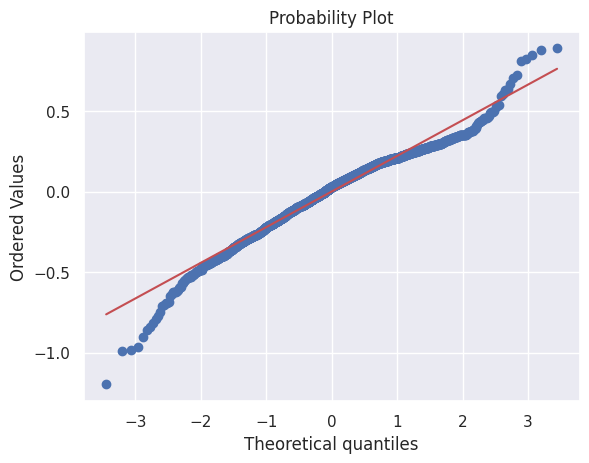

In [198]:
import pylab
import scipy.stats as stats

stats.probplot(df_pred["Residuals"], dist="norm", plot=pylab)
plt.show()

* The residuals more or less follow a straight line except for the tails.
* Let's check the results of the Shapiro-Wilk test.

In [199]:
stats.shapiro(df_pred["Residuals"])

ShapiroResult(statistic=np.float64(0.9760977984612943), pvalue=np.float64(1.0623150720753965e-19))

* The residuals are approximately normal, though not perfectly so.

* This small deviation usually does not invalidate the model, especially since your RMSE, MAE, and R-squared indicate strong predictive performance.

* **So, the assumption is satisfied.**

**TEST FOR HOMOSCEDASTICITY**

In [200]:
import statsmodels.stats.api as sms
from statsmodels.compat import lzip

name = ["F statistic", "p-value"]
test = sms.het_goldfeldquandt(df_pred["Residuals"], x_train3)
lzip(name, test)

[('F statistic', np.float64(1.1120145262078978)),
 ('p-value', np.float64(0.03321596674863774))]

**Since 0.0332 is also less than 0.05, it indicates statistical significance at the 5% level.**

Interpretation in context of the F-statistic

The F-statistic tests whether at least one of the regression coefficients is different from zero.

Here:

F = 1.112

p-value = 0.0332 → small enough to reject the null hypothesis

Meaning: the model has some predictive power; at least one predictor significantly affects the target variable.

**Predictions on test data**

In [201]:
# predictions on the test set
pred = olsmod2.predict(x_test3)

df_pred_test = pd.DataFrame({"Actual": y_test, "Predicted": pred})
df_pred_test.sample(10, random_state=1)

,Actual,Predicted
1995,4.566741,4.396478
2341,3.696103,3.965713
1913,3.592093,3.713579
688,4.306495,4.119371
650,4.522115,5.075320
2291,4.259294,4.401022
40,4.997685,5.484318
1884,3.875359,4.059030
2538,4.206631,4.028775
45,5.380450,5.279031


*   We can observe here that our model has returned pretty good prediction results, and the actual and predicted values are comparable




## Final Model

In [202]:
x_train_final = x_train3.copy()
x_test_final = x_test3.copy()

In [203]:
olsmodel_final = sm.OLS(y_train, x_train_final).fit()
print(olsmodel_final.summary())

                              OLS Regression Results                             
Dep. Variable:     normalized_used_price   R-squared:                       0.843
Model:                               OLS   Adj. R-squared:                  0.843
Method:                    Least Squares   F-statistic:                     1177.
Date:                   Mon, 22 Sep 2025   Prob (F-statistic):               0.00
Time:                           06:27:53   Log-Likelihood:                 186.34
No. Observations:                   2417   AIC:                            -348.7
Df Residuals:                       2405   BIC:                            -279.2
Df Model:                             11                                         
Covariance Type:               nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
co

In [204]:
# checking model performance on train set (seen 70% data)
print("Training Performance\n")
olsmodel_final_train_perf = model_performance_regression(
    olsmodel_final, x_train_final, y_train
)
olsmodel_final_train_perf

Training Performance



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,0.224017,0.177705,0.843391,0.842609,4.220733


In [205]:
# checking model performance on test set (seen 30% data)
print("Test Performance\n")
olsmodel_final_test_perf = model_performance_regression(
    olsmodel_final, x_test_final, y_test
)
olsmodel_final_test_perf

Test Performance



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,0.227505,0.178144,0.846191,0.844389,4.236806


* The model is able to explain 84% of the variation in the data.

* This indicates a strong fit and that the predictors capture most of the important factors affecting used device price.

* The train and test RMSE and MAE are low and comparable. So, our model is not suffering from overfitting.

* The MAPE on the test set suggests we can predict within 4.2% of the anime ratings

* Hence, we can conclude the model olsmodel_final is good for prediction as well as inference purposes.

**Prediction Accuracy:**

RMSE: Train = 0.224, Test = 0.228 => predictions are close to actual values.

MAE: Train = 0.178, Test = 0.178 => on average, predictions deviate by 0.178 units.

MAPE: Train => 4.22%, Test ≈ 4.24% => predictions are within 4% of actual values.

The model is accurate and reliable.

## Actionable Insights and Recommendations

**Conclusions**

**Price Drivers:**

* The normalized new price is the strongest predictor of used device price.

* Device specifications such as screen size, RAM, main and selfie cameras, weight, and release year significantly influence used device pricing.

* Device age negatively affects price – older devices sell for less.

**Brand Impact:**

* Certain brands, including OnePlus, Realme, Xiaomi, show a positive effect on used price.

* Other brands have minimal impact, suggesting that brand premium is stronger for specific popular brands.

**Market Trends:**

* Devices with larger screens (>6 inches) and better selfie cameras (>8MP) are more prevalent in the market, indicating consumer preference for entertainment and photography features.

* Android devices dominate the used device market, particularly brands like Samsung, Xiaomi, Huawei, and Oppo.

**Model Performance:**

* The regression model explains 84% of variance in used device prices (Adjusted R-squared = 0.844).

* Training and test metrics (RMSE, MAE, MAPE) are close, indicating good generalization and no overfitting.

* Residual analysis shows minor deviations from normality, which do not significantly affect model predictions.


**Recommendations**

**For Buyers:**

* Consider devices with higher RAM, newer release year, and better cameras, as these retain value better in the used market.

* Popular brands like OnePlus, Xiaomi, and Realme may offer better resale value.

**For Sellers / Businesses:**

* Focus on devices with high-demand specifications (screen size, cameras, battery, RAM) to maximize resale price.

* Price used devices based on normalized new price and key specs, as these factors strongly predict used value.

**For Data and Modeling:**

* The final model is robust for predicting used device prices, but continuous updates with new device releases will maintain accuracy.

* Consider log-transforming prices or monitoring residuals for extreme outliers to further improve predictions.

**Market Strategy:**

* Devices with large batteries and entertainment-friendly features should be highlighted in marketing for higher resale value.

* Android devices dominate the used market; strategies should account for brand-specific demand and device specs.

___